# 05 · Drug names: the DiAna dictionary

For anyone checking how Open Altio reads each drug name to its ingredients. FDA publishes each drug name as the reporter or company typed it: `HUMIRA`, `Humira 40 mg/0.8 ml pen`, `ADALIMUMAB-AATY`. The drug-name step (`rules/drug-names.md`, `src/open_altio/faers/drugnames/`) reads each one through the open **DiAna dictionary** (Fusaroli et al., *Drug Safety* 2024;47:271-284, [PMC10874306](https://pmc.ncbi.nlm.nih.gov/articles/PMC10874306/)) into `drug_substance_T`, with our reviewed corrections beside it (`mappings/faers/drug_names/`). This notebook measures what DiAna gives, what it leaves, where it is wrong, and what later steps would receive (WHO drug classes, RxNorm codes, label flags; none of them is built yet). It ends with the decisions its findings back.

DiAna maps each spelling to a **substance**: international names (INN) without their salts, a combination's ingredients sorted and joined with `;`, broad groups for vitamins, minerals, vaccines and herbals, `unspecified` and class terms where the name says no more, and `, trial` on investigational products.

**Grain.** A **drug record** is one drug of one report in `drug_latest_T`, keyed by (`era_T`, `primaryid`, `quarter_T`, `drug_seq`). Since 2024Q4 FDA writes some records on one row per dose; the rows of a record share its name, so every count here is of drug records or of cases, never of rows. A **spelling** is a drug name after DiAna's own light cleaning, its key. A **case** is a case of the default case set (probable duplicates left out) where a chart counts cases, and a drug is a **suspect** when FDA codes it PS or SS. "Quarter" is the quarter of the case's latest version. Every chart's subtitle says whether it counts distinct spellings, drug records or cases.

**What it reads.** A release folder built by the command line (`open-altio demo` or `open-altio build`): `RELEASE` in the first code cell, or `OPEN_ALTIO_RELEASE`. When the release does not carry the drug-name tables, the first cell runs the pipeline's own step on it, so what is measured is what a release carries. Reference files, never committed:

| where | file | source | licence |
|---|---|---|---|
| `reference/` in Open Altio's data folder, or `OPEN_ALTIO_DIANA_DICTIONARY` (where `open-altio build` reads it; fetched there when missing) | `DiAna_dictionary.csv` | OSF project [zqu89](https://osf.io/zqu89/), file dated 2026-03-20, <https://osf.io/download/n2dgz/>. Any other file is refused: rule `drug-names` pins its SHA-256 | CC BY 4.0 (Fusaroli et al.) |
| `OPEN_ALTIO_DIANA_CHECKED` | `drugnames_standardized.csv` | the same project and date, <https://osf.io/download/afnxp/>; adds DiAna's `Checked` flag (checked by hand) | CC BY 4.0 |
| `OPEN_ALTIO_RXNORM_DIR` | `rrf/RXNCONSO.RRF`, `rrf/RXNREL.RRF` | NLM, RxNorm Current Prescribable Content of 5 October 2026, <https://download.nlm.nih.gov/rxnorm/RxNorm_full_prescribe_10052026.zip> | none: public domain (section 3) |

```sh
REF=reference; mkdir -p $REF/diana $REF/rxnorm
curl -L -o $REF/diana/drugnames_standardized.csv https://osf.io/download/afnxp/
curl -L -o $REF/rxnorm/rxnorm.zip https://download.nlm.nih.gov/rxnorm/RxNorm_full_prescribe_10052026.zip
(cd $REF/rxnorm && unzip rxnorm.zip rrf/RXNCONSO.RRF rrf/RXNREL.RRF)
```

Working tables go to a scratch DuckDB beside the executed notebook (`notebooks/out/`). Nothing is written to the release.

Sections: before 1, how a spelling meets the dictionary; 1 coverage; 2 what DiAna does not map, and the quarterly top-up; 3 DiAna against RxNorm; 4 a product as a user finds it; 5 the trial mark; 6 a light check of DiAna's quality, and our corrections; 7 what the drug classes and label steps receive; Decisions. Each section ends with one item per chart: what it **shows**, its **point**, and **so what** for a decision or the build.

In [1]:
import json
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from open_altio import rulebook
from open_altio.faers.drugnames import dictionary, substances
from open_altio.faers.insights.cards import compute_cards
from open_altio.faers.insights.cards.notebook import (
    SERIES,
    mark_quarters,
    out_dir,
    plot_card,
    quarter_ticks,
    setup,
    title,
    write_cards,
)
from open_altio.faers.insights.source import release_folder
from open_altio.faers.reader import read_manifest, register_release

setup(colwidth=70)
BACKS = "Backs: rules/drug-names.md"


def need(name):
    value = os.environ.get(name)
    assert value, f"set {name} (see the first cell)"
    return Path(value).expanduser()


# The release this notebook reads; None reads $OPEN_ALTIO_RELEASE.
# No release yet? Build one with `open-altio demo` or `open-altio build`.
RELEASE = None
SOURCE = release_folder(RELEASE)
# where open-altio build reads the dictionary; fetched by checksum when missing
DIANA = dictionary.checked_file(dictionary.default_path())
CHECKED = need("OPEN_ALTIO_DIANA_CHECKED")  # DiAna's drugnames_standardized.csv
RXNORM = need("OPEN_ALTIO_RXNORM_DIR") / "rrf"  # NLM's prescribable RxNorm, unpacked
WORK = out_dir() / "05_drug_names"
WORK.mkdir(parents=True, exist_ok=True)
DB = WORK / f"{SOURCE.name}.duckdb"
if DB.exists():
    DB.unlink()  # rebuilt on every run, so the tables are always this release's
con = duckdb.connect(str(DB))
# other jobs share the machine
con.execute(
    "SET memory_limit = '6GB'; SET threads = 4; SET max_temp_directory_size = '20GB'; "
    f"SET preserve_insertion_order = false; SET temp_directory = '{WORK / 'tmp'}'"
)
register_release(con, SOURCE, temporary=True)


def q(sql):
    return con.execute(sql).fetchdf()


# The drug-name step: the release's own tables when it carries them, else the pipeline's step
# run here on its drug rows.
manifest = read_manifest(SOURCE)
if "drug_substance_T" in manifest["tables"]:
    STEP = manifest["drug_names"]
else:
    STEP = substances.build(con, DIANA)

# One row per drug record: FDA writes some records on one row per dose, so every count here is
# of records or of cases.
con.execute("""
CREATE TABLE rec_T AS
WITH r AS (SELECT era_T, primaryid, quarter_T, drug_seq, any_value(drugname) AS drugname, any_value(prod_ai) AS prod_ai,
                  any_value(role_cod) AS role_cod FROM drug_latest_T GROUP BY ALL)
SELECT r.*, s.substance_T, s.substance_source_T, s.diana_trial_T, c.case_key_T, c.dup_kept_T
FROM r JOIN drug_substance_T s USING (era_T, primaryid, quarter_T, drug_seq)
JOIN case_latest_T c USING (era_T, primaryid, quarter_T)""")
rows, records = con.execute(
    "SELECT (SELECT count(*) FROM drug_latest_T), (SELECT count(*) FROM rec_T)"
).fetchone()

print(
    "release:",
    SOURCE.name,
    "| dictionary:",
    STEP["dictionary"]["file"],
    STEP["dictionary"]["published"],
    STEP["dictionary"]["sha256"][:16],
)
print(
    f"drug rows {rows:,}; drug records {records:,} ({rows - records:,} rows are a record's further dose rows)"
)
pd.Series(STEP["records_by_source"], name="drug records by where their ingredients came from")

release: 2026Q2-final-v3 | dictionary: DiAna_dictionary.csv 2026-03-20 549162fd93d98104
drug rows 75,087,571; drug records 74,375,352 (712,219 rows are a record's further dose rows)


diana_name       72774950
diana_prod_ai      139806
correction         450478
none              1010118
Name: drug records by where their ingredients came from, dtype: int64

## How a spelling meets the dictionary

DiAna's dictionary is keyed by a drug name after DiAna's 2023 cleaning (`Cleaning_script.R`, lines 314 to 320): lower case, one trailing period removed, spaces collapsed, leading and trailing punctuation stripped twice (keeping brackets), and no space just inside a bracket. The step builds the same key from FDA's raw `drugname` (`dictionary.key_sql`, checked against a line-by-line reimplementation of the R code on every distinct name and `prod_ai` in the release) and looks it up. DiAna's 2026 rewrite (Hygieia) uses a lighter key, but the dictionary still carries the 2023 form.

**Two ways to count the same four groups.** The two panels below show the same four groups of spellings, counted two ways: on the left, how many distinct spellings fall in each group; on the right, how many drug records use them. Neither is a part of the other. A small example: 10 reports, 9 say "Humira" and 1 says "Humria pen". That is 2 spellings and 10 drug records. If DiAna lacks "humria pen", 1 of 2 spellings is unmatched (50%), but only 1 of 10 records (10%). FAERS is like that at scale: most spellings are rare.

**The four groups.** *Checked by hand:* DiAna gives a substance and its authors checked the spelling. *Not checked:* a substance, mapped in bulk. *Listed, no substance:* DiAna has the spelling and left it without an ingredient (`NA`); our lookup did not fail. *Not in the dictionary:* DiAna has never seen the spelling.

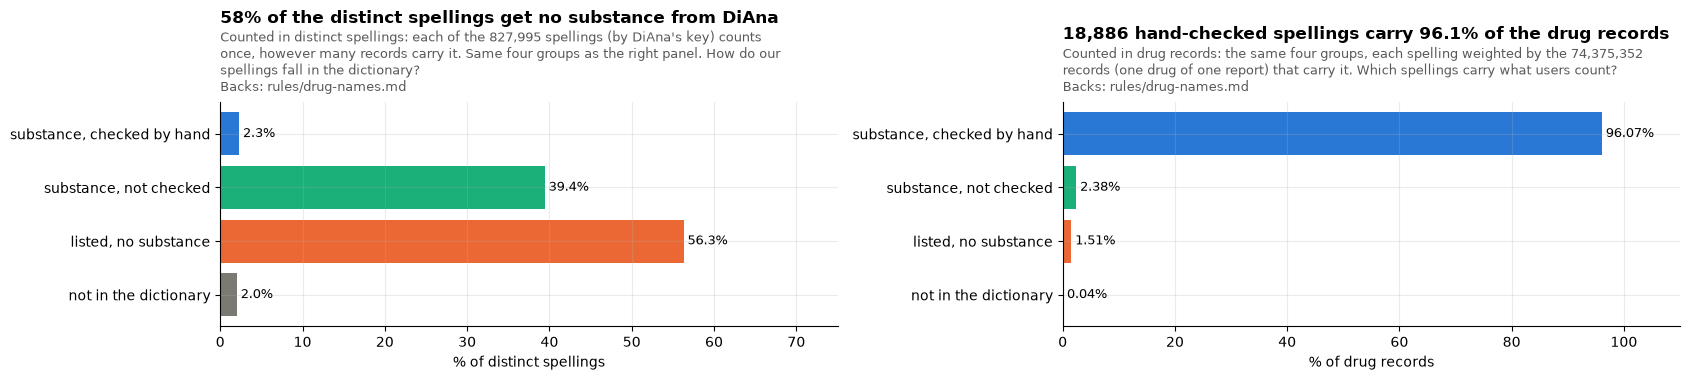

,dictionary_entries,with_a_substance,checked_by_hand,distinct_substances,combinations,trial_marked,unspecified_or_class
0,858560,347625,18896,13797,51837,249,9568


,spellings,drug_records,pct_spellings,pct_records
status,,,,
"substance, checked by hand",18886,71455590.0,2.28,96.07
"substance, not checked",326371,1769451.0,39.42,2.38
"listed, no substance",466074,1121416.0,56.29,1.51
not in the dictionary,16664,28892.0,2.01,0.04


In [2]:
# DiAna's dictionary as published: one row per key. 'NA' means DiAna saw the spelling and gave no substance.
con.execute(f"""
CREATE TEMP TABLE diana_T AS
WITH d AS (SELECT drugname AS key_T, any_value(nullif(Substance, 'NA')) AS substance_raw
           FROM read_csv('{DIANA}', delim=';', header=true, quote='"', all_varchar=true) GROUP BY 1),
     c AS (SELECT drugname AS key_T, bool_or(Checked = 'TRUE') AS checked_T
           FROM read_csv('{CHECKED}', delim=';', header=true, quote='"', all_varchar=true) GROUP BY 1)
SELECT key_T, substance_raw,
       regexp_replace(substance_raw, ',\\s*trial', '', 'g') AS substance_T,
       regexp_matches(substance_raw, ',\\s*trial') AS trial_T,
       substance_raw LIKE '%unspecified%' OR substance_raw IN ('no medication', 'no drug') AS unspecified_T,
       coalesce(c.checked_T, false) AS checked_T
FROM d LEFT JOIN c USING (key_T)""")
# every distinct FDA spelling, its key (the pipeline's: dictionary.key_sql) and how many drug records carry it
con.execute(f"""CREATE TEMP TABLE spell_T AS
SELECT drugname, {dictionary.key_sql("drugname")} AS key_T, count(*) AS records_T FROM rec_T WHERE drugname IS NOT NULL GROUP BY 1""")
comp = (
    q("""
SELECT CASE WHEN m.key_T IS NULL THEN 'not in the dictionary' WHEN m.substance_T IS NULL THEN 'listed, no substance'
            WHEN m.checked_T THEN 'substance, checked by hand' ELSE 'substance, not checked' END AS status,
       count(*) AS spellings, sum(s.records_T) AS drug_records
FROM (SELECT key_T, sum(records_T) AS records_T FROM spell_T GROUP BY 1) s LEFT JOIN diana_T m USING (key_T)
GROUP BY 1""")
    .set_index("status")
    .loc[
        [
            "substance, checked by hand",
            "substance, not checked",
            "listed, no substance",
            "not in the dictionary",
        ]
    ]
)
comp["pct_spellings"] = (100 * comp.spellings / comp.spellings.sum()).round(2)
comp["pct_records"] = (100 * comp.drug_records / comp.drug_records.sum()).round(2)
size = q("""SELECT count(*) AS dictionary_entries, count(substance_T) AS with_a_substance, count(*) FILTER (WHERE checked_T) AS checked_by_hand,
  count(DISTINCT substance_T) AS distinct_substances, count(*) FILTER (WHERE substance_T LIKE '%;%') AS combinations,
  count(*) FILTER (WHERE trial_T) AS trial_marked, count(*) FILTER (WHERE unspecified_T) AS unspecified_or_class FROM diana_T""")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 3.9))
colors = [SERIES[0], SERIES[2], SERIES[1], SERIES[6]]
a1.barh(comp.index[::-1], comp.pct_spellings[::-1], color=colors[::-1])
a1.set_xlabel("% of distinct spellings")
a1.set_xlim(0, 75)
for y, v in enumerate(comp.pct_spellings[::-1]):
    a1.text(v, y, f" {v:.1f}%", va="center", fontsize=9)
no_sub = comp.pct_spellings[["listed, no substance", "not in the dictionary"]].sum()
title(
    a1,
    f"{no_sub:.0f}% of the distinct spellings get no substance from DiAna",
    f"Counted in distinct spellings: each of the {int(comp.spellings.sum()):,} spellings (by DiAna's key) counts once, however many records carry it. "
    "Same four groups as the right panel.",
    "How do our spellings fall in the dictionary?",
    BACKS,
    width=88,
)
a2.barh(comp.index[::-1], comp.pct_records[::-1], color=colors[::-1])
a2.set_xlabel("% of drug records")
a2.set_xlim(0, 110)
for y, v in enumerate(comp.pct_records[::-1]):
    a2.text(v, y, f" {v:.2f}%", va="center", fontsize=9)
chk = comp.loc["substance, checked by hand"]
title(
    a2,
    f"{int(chk.spellings):,} hand-checked spellings carry {chk.pct_records:.1f}% of the drug records",
    f"Counted in drug records: the same four groups, each spelling weighted by the {records:,} records (one drug of one report) that carry it.",
    "Which spellings carry what users count?",
    BACKS,
    width=88,
)
plt.tight_layout()
plt.show()
display(size)
comp

## 1 · Coverage, 2004Q1 to 2026Q2

A drug record is **mapped** when its spelling has a DiAna substance: a named **substance**, or an **unspecified or class** term (`vitamins, unspecified`) that is mapped but says little. Where the name has none, the step reads FDA's own active-ingredient field `prod_ai` (filled from 2014Q3) through the same dictionary, whole or split on FDA's `\` with every part found: the **fallback**.

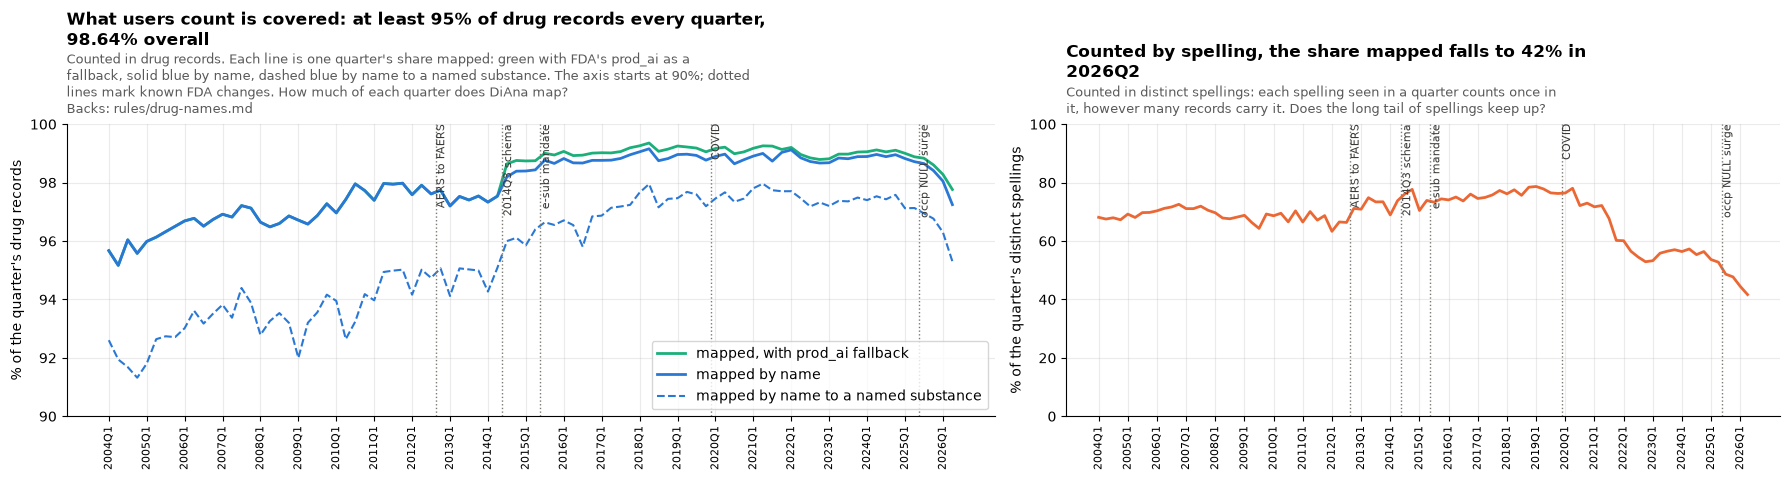

distinct spellings mapped, quarters before 2021: 63% to 79%


,status,drug_records,pct
0,substance,71814043.0,96.56
1,unspecified or class,1410998.0,1.90
2,unmapped,1010118.0,1.36
3,via prod_ai,140193.0,0.19


,quarter_T,records,substance,mapped,mapped_with_prod_ai,prod_ai_filled,spellings,pct_spellings_mapped
76,2023q1,1275742.0,97.20,98.68,98.82,97.34,26789,53.26
77,2023q2,1303635.0,97.37,98.84,98.97,97.48,25143,55.83
78,2023q3,1280009.0,97.36,98.82,98.98,97.88,24253,56.52
79,2023q4,1289135.0,97.49,98.89,99.05,98.02,23697,57.02
80,2024q1,1301448.0,97.40,98.89,99.06,98.03,23122,56.40
81,2024q2,1285592.0,97.53,98.96,99.12,98.08,21951,57.27
82,2024q3,1323965.0,97.43,98.89,99.05,98.19,22626,55.34
83,2024q4,1359265.0,97.58,98.96,99.11,98.44,22358,56.39
84,2025q1,1339552.0,97.12,98.82,99.00,98.32,23405,53.65
85,2025q2,1290073.0,97.13,98.72,98.88,98.26,23576,52.76


In [3]:
# where the name has no DiAna substance, the step reads FDA's prod_ai (rule drug-names); rec_T carries its answer
con.execute("""CREATE TEMP TABLE cov_T AS
SELECT r.quarter_T, r.role_cod,
  CASE WHEN m.substance_T IS NULL THEN 'unmapped' WHEN m.unspecified_T THEN 'unspecified or class' ELSE 'substance' END AS by_name,
  CASE WHEN m.substance_T IS NOT NULL THEN (CASE WHEN m.unspecified_T THEN 'unspecified or class' ELSE 'substance' END)
       WHEN r.substance_source_T <> 'none' THEN 'via prod_ai' ELSE 'unmapped' END AS with_fallback,
  r.prod_ai IS NOT NULL AS has_prod_ai, count(*) AS n
FROM rec_T r LEFT JOIN spell_T s USING (drugname) LEFT JOIN diana_T m USING (key_T) GROUP BY ALL""")
overall = q(
    "SELECT with_fallback AS status, sum(n) AS drug_records, round(100.0 * sum(n) / sum(sum(n)) OVER (), 2) AS pct FROM cov_T GROUP BY 1 ORDER BY 2 DESC"
)
byq = q("""SELECT quarter_T, sum(n) AS records,
  100.0 * sum(n) FILTER (WHERE by_name = 'substance') / sum(n) AS substance,
  100.0 * sum(n) FILTER (WHERE by_name <> 'unmapped') / sum(n) AS mapped,
  100.0 * sum(n) FILTER (WHERE with_fallback <> 'unmapped') / sum(n) AS mapped_with_prod_ai,
  100.0 * sum(n) FILTER (WHERE has_prod_ai) / sum(n) AS prod_ai_filled
FROM cov_T GROUP BY 1 ORDER BY 1""")
con.execute(
    "CREATE TEMP TABLE keyq_T AS SELECT r.quarter_T, s.key_T, count(*) AS n FROM rec_T r JOIN spell_T s USING (drugname) GROUP BY ALL"
)
kq = q("""SELECT quarter_T, count(*) AS spellings, 100.0 * avg((m.substance_T IS NOT NULL)::INT) AS pct_spellings_mapped
FROM keyq_T k LEFT JOIN diana_T m USING (key_T) GROUP BY 1 ORDER BY 1""")
tot = overall.set_index("status").pct
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 4.9), gridspec_kw={"width_ratios": [1.3, 1]})
x = range(len(byq))
a1.plot(x, byq.mapped_with_prod_ai, label="mapped, with prod_ai fallback", color=SERIES[2])
a1.plot(x, byq.mapped, label="mapped by name", color=SERIES[0])
a1.plot(
    x, byq.substance, label="mapped by name to a named substance", color=SERIES[0], ls="--", lw=1.5
)
a1.set_ylim(90, 100)
a1.set_ylabel("% of the quarter's drug records")
title(
    a1,
    f"What users count is covered: at least {int(byq.mapped.min())}% of drug records every quarter, {100 - tot['unmapped']:.2f}% overall",
    "Counted in drug records. Each line is one quarter's share mapped: green with FDA's prod_ai as a fallback, solid blue by name, "
    "dashed blue by name to a named substance. The axis starts at 90%; dotted lines mark known FDA changes.",
    "How much of each quarter does DiAna map?",
    BACKS,
    width=104,
)
quarter_ticks(a1, byq.quarter_T)
mark_quarters(a1, byq.quarter_T)
a1.legend(loc="lower right")
a2.plot(range(len(kq)), kq.pct_spellings_mapped, color=SERIES[1])
a2.set_ylim(0, 100)
a2.set_ylabel("% of the quarter's distinct spellings")
title(
    a2,
    f"Counted by spelling, the share mapped falls to {kq.pct_spellings_mapped.iloc[-1]:.0f}% in {kq.quarter_T.iloc[-1].upper()}",
    "Counted in distinct spellings: each spelling seen in a quarter counts once in it, however many records carry it.",
    "Does the long tail of spellings keep up?",
    width=80,
)
quarter_ticks(a2, kq.quarter_T)
mark_quarters(a2, kq.quarter_T)
plt.tight_layout()
plt.show()
pre = kq[kq.quarter_T < "2021q1"].pct_spellings_mapped
print(f"distinct spellings mapped, quarters before 2021: {pre.min():.0f}% to {pre.max():.0f}%")
display(overall)
byq.merge(kq, on="quarter_T").tail(14).round(2)

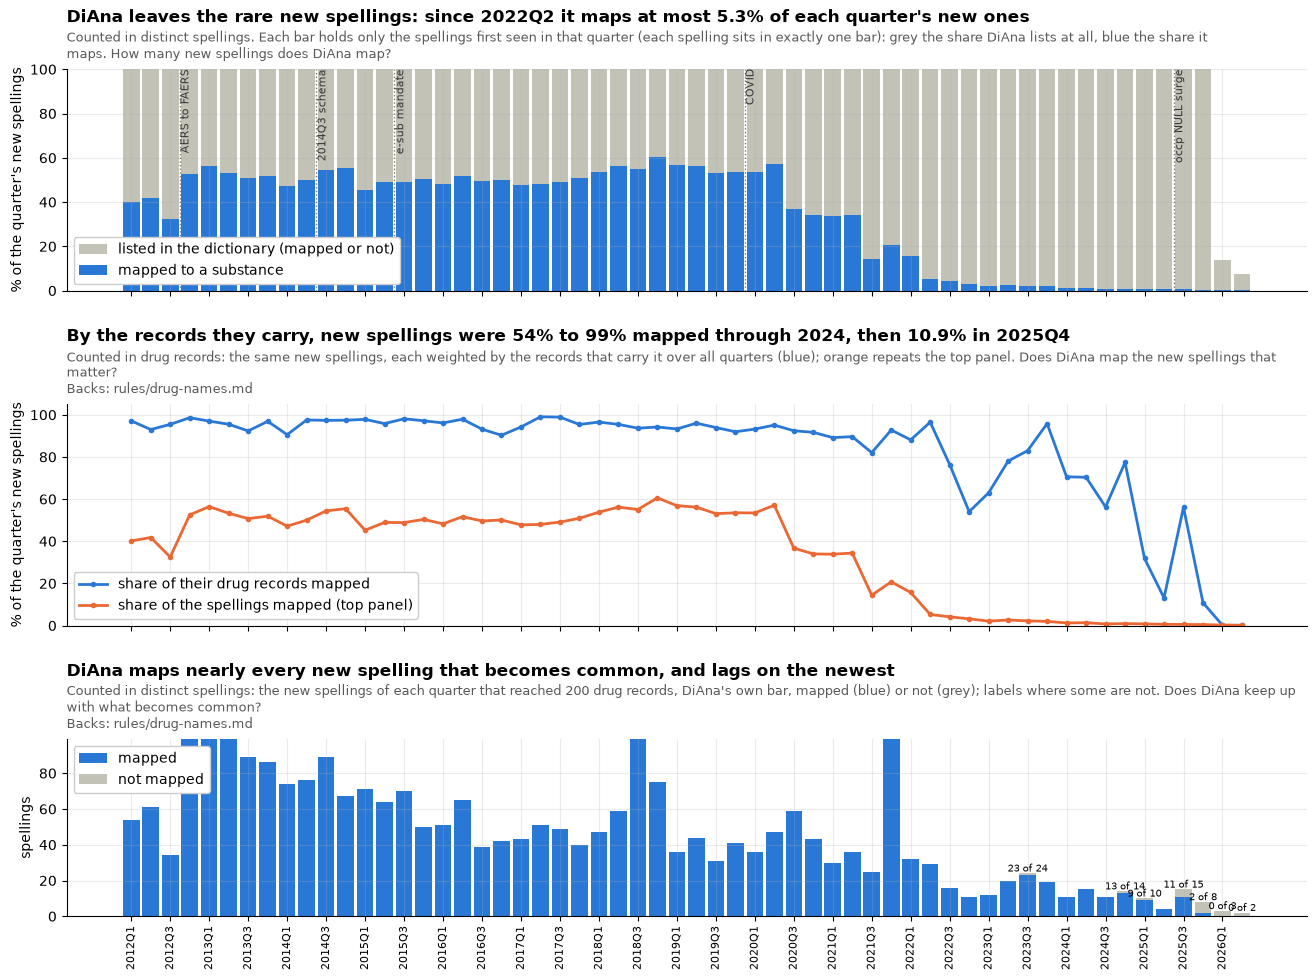

'First seen' reads each spelling on its records' latest case versions: of the spellings first seen in 2026Q1, 13.9% are already in the March 2026 dictionary, which saw earlier versions of those cases.


,first_quarter,new_spellings,their_records,pct_spellings_mapped,pct_listed,pct_records_mapped,reached_200,reached_200_mapped,reached_5
36,2021q1,11383,123488.0,33.9,100.0,89.2,30,30,765
37,2021q2,10294,115075.0,34.4,100.0,89.6,36,36,622
38,2021q3,10018,79431.0,14.4,100.0,82.0,25,25,496
39,2021q4,7910,323541.0,20.7,100.0,92.8,212,212,1379
40,2022q1,7028,123089.0,15.7,100.0,88.1,32,32,677
41,2022q2,6872,417130.0,5.3,100.0,96.5,29,29,606
42,2022q3,7347,69213.0,4.2,100.0,76.4,16,16,599
43,2022q4,7673,33227.0,3.2,99.9,54.0,11,11,543
44,2023q1,7065,34243.0,2.1,100.0,63.0,12,12,393
45,2023q2,6071,52144.0,2.7,100.0,78.0,20,20,338


In [4]:
# each spelling's first quarter (of its records' latest case versions), its records over all quarters, and whether DiAna maps it
con.execute("""CREATE TEMP TABLE first_T AS
SELECT k.key_T, min(k.quarter_T) AS first_quarter_T, sum(k.n) AS records_T, any_value(m.substance_T IS NOT NULL) AS mapped_T,
       any_value(m.key_T IS NOT NULL) AS listed_T
FROM keyq_T k LEFT JOIN diana_T m USING (key_T) GROUP BY 1""")
first = q("""SELECT first_quarter_T AS first_quarter, count(*) AS new_spellings, sum(records_T) AS their_records,
  100.0 * avg(mapped_T::INT) AS pct_spellings_mapped, 100.0 * avg(listed_T::INT) AS pct_listed,
  100.0 * sum(records_T) FILTER (WHERE mapped_T) / sum(records_T) AS pct_records_mapped,
  count(*) FILTER (WHERE records_T >= 200) AS reached_200, count(*) FILTER (WHERE records_T >= 200 AND mapped_T) AS reached_200_mapped,
  count(*) FILTER (WHERE records_T >= 5) AS reached_5
FROM first_T WHERE first_quarter_T >= '2012q1' GROUP BY 1 ORDER BY 1""")
fig, (a1, a2, a3) = plt.subplots(
    3, 1, figsize=(16, 11), sharex=True, gridspec_kw={"height_ratios": [1, 1, 0.8], "hspace": 0.55}
)
x = np.arange(len(first))
a1.bar(
    x,
    first.pct_listed,
    color=SERIES[7],
    width=0.85,
    label="listed in the dictionary (mapped or not)",
)
a1.bar(x, first.pct_spellings_mapped, color=SERIES[0], width=0.85, label="mapped to a substance")
a1.set_ylim(0, 100)
a1.set_ylabel("% of the quarter's new spellings")
late = first.first_quarter >= "2022q2"
title(
    a1,
    f"DiAna leaves the rare new spellings: since 2022Q2 it maps at most {first.loc[late, 'pct_spellings_mapped'].max():.1f}% of each quarter's new ones",
    "Counted in distinct spellings. Each bar holds only the spellings first seen in that quarter (each spelling sits in exactly one bar): "
    "grey the share DiAna lists at all, blue the share it maps.",
    "How many new spellings does DiAna map?",
    width=190,
)
a1.legend(loc="lower left", framealpha=1)
a2.plot(
    x,
    first.pct_records_mapped,
    color=SERIES[0],
    marker="o",
    ms=3,
    label="share of their drug records mapped",
)
a2.plot(
    x,
    first.pct_spellings_mapped,
    color=SERIES[1],
    marker="o",
    ms=3,
    label="share of the spellings mapped (top panel)",
)
a2.set_ylim(0, 105)
a2.set_ylabel("% of the quarter's new spellings")
r24 = first[
    (first.first_quarter >= "2012q1") & (first.first_quarter <= "2024q4")
].pct_records_mapped
q25 = first.set_index("first_quarter").pct_records_mapped
title(
    a2,
    f"By the records they carry, new spellings were {r24.min():.0f}% to {r24.max():.0f}% mapped through 2024, then {q25.get('2025q4', float('nan')):.1f}% in 2025Q4",
    "Counted in drug records: the same new spellings, each weighted by the records that carry it over all quarters (blue); orange repeats the top panel.",
    "Does DiAna map the new spellings that matter?",
    BACKS,
    width=190,
)
a2.legend(loc="lower left", framealpha=1)
m, u = first.reached_200_mapped.values, (first.reached_200 - first.reached_200_mapped).values
a3.bar(x, m, color=SERIES[0], width=0.85, label="mapped")
a3.bar(x, u, bottom=m, color=SERIES[7], width=0.85, label="not mapped")
a3.set_ylabel("spellings")
a3.set_ylim(0, max(80, int(np.percentile(first.reached_200, 90)) + 10))
for i in range(len(first)):
    if u[i] > 0:
        a3.text(x[i], m[i] + u[i] + 1, f"{m[i]} of {m[i] + u[i]}", ha="center", fontsize=7)
title(
    a3,
    "DiAna maps nearly every new spelling that becomes common, and lags on the newest",
    "Counted in distinct spellings: the new spellings of each quarter that reached 200 drug records, DiAna's own bar, mapped (blue) or not (grey); "
    "labels where some are not.",
    "Does DiAna keep up with what becomes common?",
    BACKS,
    width=190,
)
a3.legend(loc="upper left", framealpha=1)
quarter_ticks(a3, first.first_quarter, every=2)
mark_quarters(a1, first.first_quarter)
plt.show()
early = q(
    """SELECT 100.0 * avg(listed_T::INT) AS pct_listed FROM first_T WHERE first_quarter_T = '2026q1'"""
)
print(
    f"'First seen' reads each spelling on its records' latest case versions: of the spellings first seen in 2026Q1, "
    f"{early.pct_listed[0]:.1f}% are already in the March 2026 dictionary, which saw earlier versions of those cases."
)
first.tail(22).round(1)

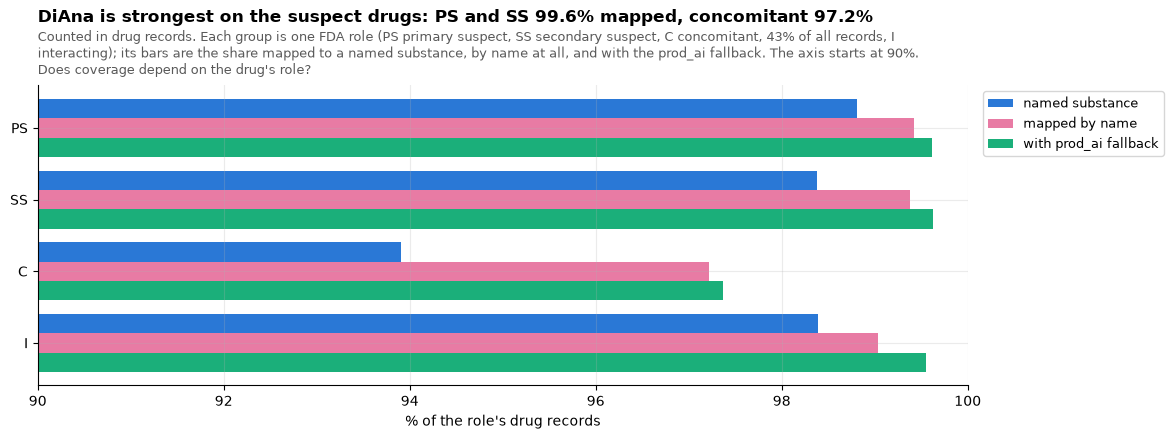

,records,substance,mapped,mapped_with_prod_ai
role_cod,,,,
C,32308241.0,93.91,97.22,97.37
SS,21154482.0,98.38,99.38,99.62
PS,20586643.0,98.81,99.42,99.62
I,325247.0,98.39,99.03,99.55
DN,733.0,99.18,99.45,99.86
NULL,6.0,83.33,100.00,100.00


In [5]:
role = q("""SELECT coalesce(role_cod, 'NULL') AS role_cod, sum(n) AS records,
  100.0 * sum(n) FILTER (WHERE by_name = 'substance') / sum(n) AS substance,
  100.0 * sum(n) FILTER (WHERE by_name <> 'unmapped') / sum(n) AS mapped,
  100.0 * sum(n) FILTER (WHERE with_fallback <> 'unmapped') / sum(n) AS mapped_with_prod_ai
FROM cov_T GROUP BY 1 ORDER BY records DESC""").set_index("role_cod")
main_roles = role.loc[["PS", "SS", "C", "I"]]
fig, ax = plt.subplots(figsize=(12, 3.9))
y = np.arange(len(main_roles))
h = 0.27
for i, (col, lab) in enumerate(
    [
        ("substance", "named substance"),
        ("mapped", "mapped by name"),
        ("mapped_with_prod_ai", "with prod_ai fallback"),
    ]
):
    ax.barh(
        y + (i - 1) * h, main_roles[col], h, label=lab, color=[SERIES[0], SERIES[4], SERIES[2]][i]
    )
ax.set_yticks(y)
ax.set_yticklabels(main_roles.index)
ax.invert_yaxis()
ax.set_xlim(90, 100)
ax.set_xlabel("% of the role's drug records")
c_share = 100 * role.loc["C", "records"] / role.records.sum()
title(
    ax,
    f"DiAna is strongest on the suspect drugs: PS and SS {main_roles.loc[['PS', 'SS'], 'mapped_with_prod_ai'].min():.1f}% mapped, concomitant {main_roles.loc['C', 'mapped']:.1f}%",
    f"Counted in drug records. Each group is one FDA role (PS primary suspect, SS secondary suspect, C concomitant, {c_share:.0f}% of all records, I interacting); "
    "its bars are the share mapped to a named substance, by name at all, and with the prod_ai fallback. The axis starts at 90%.",
    "Does coverage depend on the drug's role?",
    width=140,
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()
role.round(2)

**What section 1 shows**, one item per chart:

- **Spellings against records, by dictionary status** (the chart before this section). *Shows:* 58% of the distinct spellings get no substance from DiAna, but they hold 1.55% of the drug records (1.51% listed with none, 0.04% never seen); the 18,886 spellings checked by hand hold 96.07%. *Point:* DiAna's value sits in a small checked core; what it misses is rare. *So what:* backs decision 1 (DiAna as the seed); the residue is a long-tail job, no reason to wait (decision 5).
- **Coverage by quarter.** *Shows:* left, in drug records: 95% to 99% of each quarter mapped; over all quarters 98.46% by name and 98.64% with `prod_ai`. Right, in distinct spellings: 63% to 79% of a quarter's spellings mapped before 2021, falling to 42% in 2026Q2. *Point:* what users count is covered steadily for 22 years; the falling right line is the rare tail, not the counts. *So what:* counts compare across years. Build with the `prod_ai` fallback (0.19 points more) and DiAna's 2023 key (decision 1). The one dip is the newest quarters: 2026Q2 is 97.25% by name, 97.76% with `prod_ai`.
- **New spellings, by the quarter they were first seen.** *Shows:* top, in distinct spellings: each bar holds only the spellings first seen in that quarter, so each spelling sits in exactly one bar. Since 2022Q2 DiAna maps at most 5.3% of each quarter's new spellings, and most 2026 spellings are not even listed (the dictionary is dated March 2026). Middle, in drug records: weighted by the records they carry, the new spellings were 54% to 99% mapped through 2024, then 31.8%, 13.1%, 56.1% and 10.9% in the four quarters of 2025, and almost none in 2026. Bottom: of the new spellings that reached 200 records, DiAna's own bar, it mapped every one through 2023Q2, then 23 of 24 (2023Q3), 13 of 14 (2024Q4), 9 of 10, 4 of 4, 11 of 15 and 2 of 8 in 2025, and 0 of 3 and 0 of 2 in 2026. A worked example, 2022Q2: 6,872 new spellings, about 360 of them mapped (5.3%); those carry 96.5% of the new spellings' 417,130 records, and the other 6,500 or so carry about 14,600 records, two each. *Point:* DiAna maps the new names that become common, leaves the rare tail on purpose (its stated aim is a translation for every term seen more than 200 times, `Cleaning_script.R` lines 328 to 331), and lags on the newest products. *So what:* the gap that matters is the newest products, where label flags matter most: our own quarterly top-up (decision 6), and an RxNorm code from the spelling itself (decision 2). "First seen" reads each spelling on its records' latest case versions, so 13.9% of the spellings first seen in 2026Q1 are already in the March 2026 dictionary, which saw earlier versions of those cases.
- **Coverage by role.** *Shows:* in drug records: PS and SS 99.62% mapped with the fallback; concomitant drugs (C, 43% of all records) 97.22% by name and 93.91% to a named substance. *Point:* DiAna is strongest on the drugs our counts use. *So what:* coverage is no reason to pick a role setting, and counting every role pulls in the vague terms; one suspect definition everywhere, PS and SS, as the statistics and the label flags use (decision 4).

### How many ingredients the spellings read down to

The methods page says how many of FDA's drug name spellings read down to how many single ingredients and how many combinations. This section counts them the way the page does and checks the page's numbers against the tables. Capitals are ignored, so `lactobacillus SPP` and `lactobacillus spp` are one ingredient. The explorer's ingredient list is every ingredient and every combination together.

All counts are of the drug records of the cases the release shows (the latest version of each case, probable duplicates left out), in every role: primary suspect, secondary suspect, interacting and concomitant. A record has its ingredients from DiAna's dictionary for its drug name, or from FDA's `prod_ai` where the name has none; records with no ingredient are left out. A combination is a record with two or more ingredients (`sacubitril;valsartan`).

FDA spellings: 993,421
single ingredients: 6,441   combinations: 9,095
methods.json: 993,421 spellings read to 6,441 single ingredients and 9,095 combinations
explorer list: 15,536 entries; with cases as primary or secondary suspect, 5,164 single ingredients



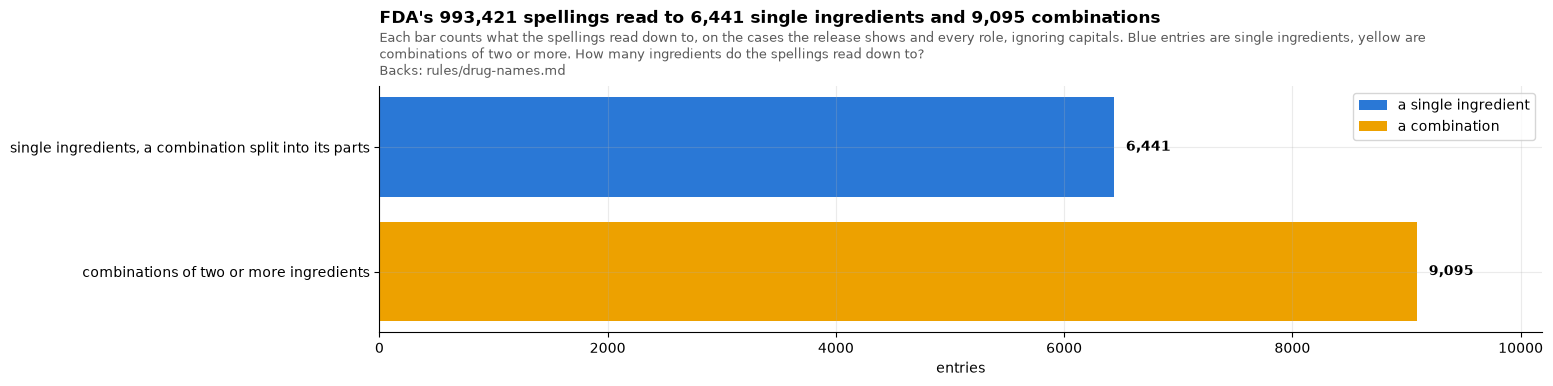

In [6]:
STEP_NUMBERS = json.loads((SOURCE / "methods.json").read_text(encoding="utf-8"))["numbers"][
    "drug_names"
]
# What the methods page prints, counted again from the tables on the cases the release shows (dup_kept_T).
K = "era_T, primaryid, quarter_T"
con.execute(
    f"CREATE OR REPLACE TEMP TABLE shown_T AS SELECT {K} FROM case_latest_T WHERE dup_kept_T"
)
D = f"(SELECT {K}, drug_seq, role_cod FROM drug_latest_T d SEMI JOIN shown_T USING ({K}))"
spellings = q(
    f"SELECT count(DISTINCT drugname) AS n FROM drug_latest_T SEMI JOIN shown_T USING ({K})"
).n[0]
# single ingredients: each record's combination split into its parts, capitals ignored
singles = q(
    f"SELECT count(DISTINCT lower(ingredient_T)) AS n FROM drug_ingredient_T i SEMI JOIN {D} USING ({K}, drug_seq) WHERE ingredient_T IS NOT NULL"
).n[0]
# combinations: the substances with two or more ingredients, capitals ignored
combos = q(
    f"SELECT count(DISTINCT lower(substance_T)) AS n FROM drug_substance_T s SEMI JOIN {D} USING ({K}, drug_seq) WHERE substance_T LIKE '%;%'"
).n[0]
# the explorer's ingredient list: every ingredient and every combination, each as its own entry
listed = singles + combos
suspect = q(f"""SELECT count(DISTINCT lower(i.ingredient_T)) AS singles FROM drug_ingredient_T i
                JOIN {D} d USING ({K}, drug_seq) WHERE d.role_cod IN ('PS', 'SS')""").singles[0]
print(f"FDA spellings: {spellings:,}")
print(f"single ingredients: {singles:,}   combinations: {combos:,}")
print(
    f"methods.json: {STEP_NUMBERS['spellings']:,} spellings read to {STEP_NUMBERS['ingredients']:,} single ingredients and {STEP_NUMBERS['combinations']:,} combinations"
)
print(
    f"explorer list: {listed:,} entries; with cases as primary or secondary suspect, {suspect:,} single ingredients"
)
print()
rows = [
    ("single ingredients, a combination split into its parts", singles, 0, singles),
    ("combinations of two or more ingredients", 0, combos, combos),
]
fig, ax = plt.subplots(figsize=(15, 3.2))
y = np.arange(len(rows))
ax.barh(y, [r[1] for r in rows], color=SERIES[0], label="a single ingredient")
ax.barh(y, [r[2] for r in rows], left=[r[1] for r in rows], color=SERIES[3], label="a combination")
for yi, r in zip(y, rows, strict=True):
    ax.text(r[1] + r[2] + 100, yi, f"{r[3]:,}", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(y)
ax.set_yticklabels([r[0] for r in rows])
ax.invert_yaxis()
ax.set_xlim(0, max(singles, combos) * 1.12)
ax.set_xlabel("entries")
ax.legend(loc="upper right")
title(
    ax,
    f"FDA's {spellings:,} spellings read to {singles:,} single ingredients and {combos:,} combinations",
    "Each bar counts what the spellings read down to, on the cases the release shows and every role, ignoring capitals. Blue entries are single ingredients, yellow are combinations of two or more.",
    "How many ingredients do the spellings read down to?",
    BACKS,
    width=165,
)
plt.show()

**What this section shows**

- **What the spellings read down to.** *Shows:* the single ingredients and the combinations the spellings read to, the two numbers the methods page prints. *Point:* FDA's spellings read to single ingredients and combinations, counted ignoring capitals, and the page's numbers equal the ones counted here from the tables. The explorer's ingredient list holds both together. *So what:* a combination is not hidden inside its parts: the page counts it once as a combination, and its ingredients once each as single ingredients.


## 2 · What DiAna does not map, and the quarterly top-up

The residue: every spelling with no DiAna substance, ranked by the drug records it carries. How many spellings make up most of it decides how much a later proposal step (rules, then a language model, then a person) has to handle. Each spelling gets one **kind** by simple rules, in this order:

1. **blank or punctuation only**
2. **trial code or blinded**: `blinded`, `placebo`, `study drug`, `investigational`, or a code like `TU-100`, `QVA149`
3. **biosimilar suffix**: a biologic name with FDA's four-letter suffix, `adalimumab-adbm`
4. **in RxNorm**: the exact spelling is a current US ingredient or brand name (section 3), so a newer drug or brand
5. **combination written out**: `\`, `;`, `+`, `&`, a `/` between letters, ` and `, ` with `
6. **known name with extra words**: the first word is a mapped spelling, `zepbound kwikpen`, `aspirin low ec`
7. **misspelling**: one word, within two letters of a mapped spelling seen at least 20 times, `nitroglycern`
8. **vague or class words**: `unknown`, `medication`, `pill`, `therapy` ...
9. **consumer product or device**: `sunscreen`, `spf`, `shampoo`, `pump`, `syringe` ...
10. **other**: foreign brands, free text, rarer errors

These rules are rough. They size the work; they are not a proposal. The second chart sizes a quarterly top-up from each quarter's own drug records, counted in the quarter they belong to.

RxNorm names read: 12,628


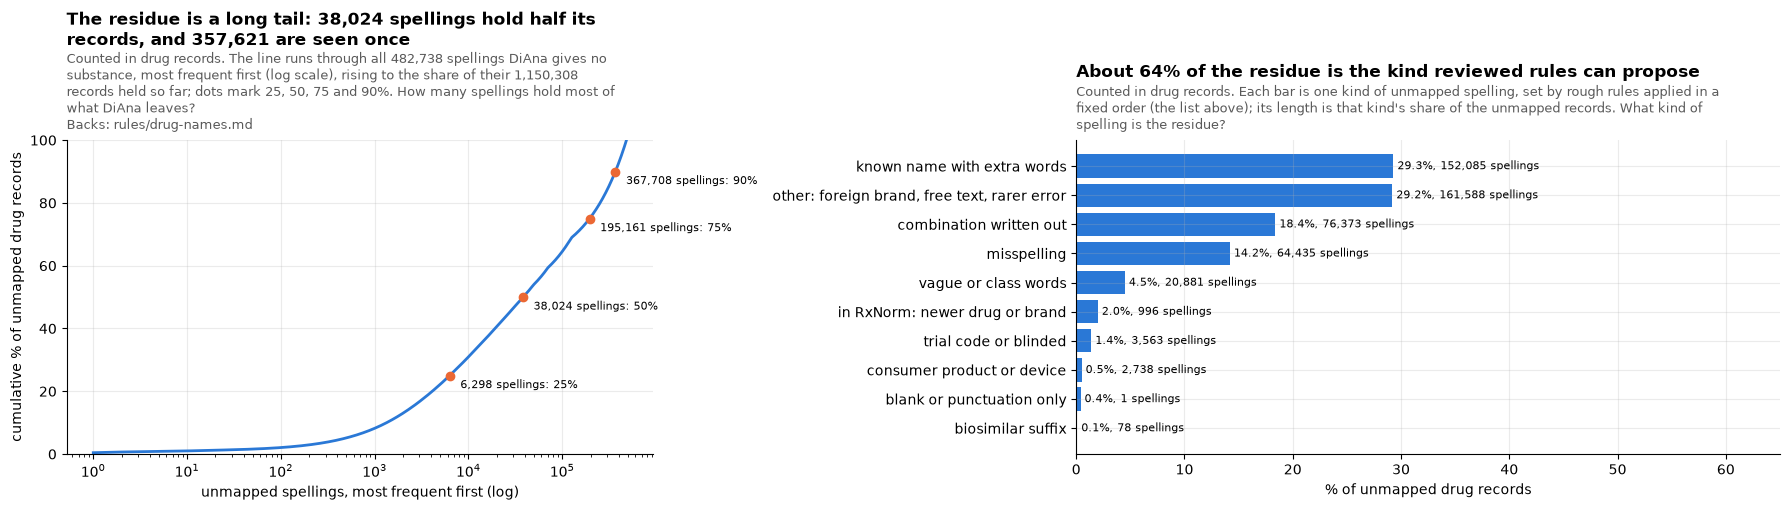

,kind,spellings,drug_records,pct_of_residue
0,known name with extra words,152085,337288.0,29.3
1,"other: foreign brand, free text, rarer error",161588,336239.0,29.2
2,combination written out,76373,211090.0,18.4
3,misspelling,64435,163018.0,14.2
4,vague or class words,20881,52156.0,4.5
5,in RxNorm: newer drug or brand,996,22758.0,2.0
6,trial code or blinded,3563,15649.0,1.4
7,consumer product or device,2738,6167.0,0.5
8,blank or punctuation only,1,4951.0,0.4
9,biosimilar suffix,78,992.0,0.1


,spellings seen,how many,% of unmapped records
0,>= 200 records,19,1.2
1,>= 100 records,143,2.5
2,>= 20 records,7562,27.3
3,>= 5 records,37606,49.9
4,>= 2 records,125117,68.9
5,>= 1 records,482738,100.0


,kind,fda_spelling,drug_records,first_seen
0,biosimilar suffix,BEVACIZUMAB-ADCD,198.0,2025q3
1,biosimilar suffix,SOTATERCEPT-CSRK,104.0,2025q1
2,biosimilar suffix,ADALIMUMAB-ADBM,73.0,2024q1
3,biosimilar suffix,TEPLIZUMAB-MZWV,73.0,2024q2
4,biosimilar suffix,ADALIMUMAB-AACF,64.0,2024q1
5,biosimilar suffix,SUTIMLIMAB-JOME,43.0,2022q2
6,blank or punctuation only,.,4951.0,NaN
7,combination written out,AVIBACTAM\AZTREONAM,141.0,2024q4
8,combination written out,CANNABIDIOL\HERBALS\TETRAHYDROCANNABINOL UNSPECIFIED,131.0,2022q2
9,combination written out,COAL TAR\COCONUT OIL\SALICYLIC ACID,127.0,2022q3


In [7]:
RX_CONSO, RX_REL = (RXNORM / "RXNCONSO.RRF").as_posix(), (RXNORM / "RXNREL.RRF").as_posix()
# RxNorm's names of ingredients (IN), precise ingredients such as salts (PIN, read as their IN), multiple-ingredient
# names (MIN, read as their INs) and brand names (BN, read as their INs); NLM's suppressed names left out
con.execute(f"""
CREATE TEMP TABLE rxname_T AS
WITH c AS (SELECT column00 AS rxcui, column12 AS tty, lower(column14) AS nm
           FROM read_csv('{RX_CONSO}', delim='|', header=false, quote='', escape='', all_varchar=true)
           WHERE column11 = 'RXNORM' AND column12 IN ('IN', 'PIN', 'MIN', 'BN') AND column16 = 'N'),
r AS (SELECT column00 AS c1, column07 AS rela, column04 AS c2
      FROM read_csv('{RX_REL}', delim='|', header=false, quote='', escape='', all_varchar=true)
      WHERE column10 = 'RXNORM' AND column07 IN ('has_tradename', 'part_of', 'has_form')),
ins AS (SELECT rxcui, nm FROM c WHERE tty = 'IN'),
ing AS (SELECT * FROM ins UNION ALL SELECT r.c1, i.nm FROM r JOIN ins i ON i.rxcui = r.c2 WHERE r.rela = 'has_form'),
each AS (SELECT c.nm AS key_T, c.tty, g.nm AS ingredient FROM c JOIN ing g USING (rxcui) WHERE c.tty IN ('IN', 'PIN')
         UNION ALL SELECT c.nm, c.tty, g.nm FROM c JOIN r ON r.c1 = c.rxcui AND r.rela = 'part_of' JOIN ing g ON g.rxcui = r.c2 WHERE c.tty = 'MIN'
         UNION ALL SELECT c.nm, c.tty, g.nm FROM c JOIN r ON r.c1 = c.rxcui AND r.rela = 'has_tradename' JOIN ing g ON g.rxcui = r.c2 WHERE c.tty = 'BN'),
ranked AS (SELECT *, CASE tty WHEN 'IN' THEN 1 WHEN 'PIN' THEN 2 WHEN 'MIN' THEN 3 ELSE 4 END AS pri FROM each),
best AS (SELECT *, min(pri) OVER (PARTITION BY key_T) AS best_pri FROM ranked)
SELECT key_T, any_value(tty) AS rx_tty_T, array_to_string(list_sort(list_distinct(list(ingredient))), ';') AS rx_ingredients_T
FROM best WHERE pri = best_pri GROUP BY 1""")
print(f"RxNorm names read: {con.execute('SELECT count(*) FROM rxname_T').fetchone()[0]:,}")
con.execute("""CREATE TEMP TABLE known_T AS
SELECT key_T, sum(records_T) AS records_T FROM spell_T JOIN diana_T USING (key_T) WHERE substance_T IS NOT NULL AND NOT unspecified_T GROUP BY 1""")
con.execute("""CREATE TEMP TABLE resid_T AS
SELECT s.key_T, sum(s.records_T) AS records_T, arg_max(s.drugname, s.records_T) AS example_T, any_value(f.first_quarter_T) AS first_quarter_T
FROM spell_T s LEFT JOIN diana_T m USING (key_T) LEFT JOIN first_T f USING (key_T) WHERE m.substance_T IS NULL GROUP BY 1""")
con.execute("""CREATE TEMP TABLE misspelt_T AS
WITH r AS (SELECT key_T FROM resid_T WHERE length(key_T) >= 5 AND NOT regexp_matches(key_T, '[ 0-9]')),
     k AS (SELECT key_T FROM known_T WHERE records_T >= 20 AND NOT regexp_matches(key_T, '[ 0-9]'))
SELECT DISTINCT r.key_T FROM r JOIN k ON left(r.key_T, 1) = left(k.key_T, 1) AND abs(length(r.key_T) - length(k.key_T)) <= 2
WHERE levenshtein(r.key_T, k.key_T) <= 2""")
con.execute(r"""CREATE TEMP TABLE kind_T AS
SELECT r.*, CASE
  WHEN r.key_T IS NULL THEN 'blank or punctuation only'
  WHEN regexp_matches(r.key_T, '\b(blinded|placebo|study drug|investigational)\b') OR regexp_matches(r.key_T, '^[a-z]{1,5}-?[0-9]{3,}[a-z0-9-]*$') THEN 'trial code or blinded'
  WHEN regexp_matches(r.key_T, '^[a-z ]+(mab|cept|stim|poetin|ase|alfa|beta|insulin|glargine|aspart|lispro)-[a-z]{4}$') THEN 'biosimilar suffix'
  WHEN x.key_T IS NOT NULL THEN 'in RxNorm: newer drug or brand'
  WHEN regexp_matches(r.key_T, '[\\;+&]|[a-z] ?/ ?[a-z]| and | with ') THEN 'combination written out'
  WHEN f.key_T IS NOT NULL THEN 'known name with extra words'
  WHEN ms.key_T IS NOT NULL THEN 'misspelling'
  WHEN regexp_matches(r.key_T, '\b(unknown|unk|unspecified|not specified|other|others|medication|medications|medicine|medicines|pill|pills|drug|drugs|therapy|treatment|supplement|supplements|agent|agents)\b') THEN 'vague or class words'
  WHEN regexp_matches(r.key_T, '\b(spf|sunscreen|lotion|shampoo|cleanser|toothpaste|deodorant|soap|wipes?|sanitizer|cpap|c-pap|pump|needle|syringe|device|strips?|monitor|lens|lenses|implant|catheter|mask|bandage|gloves)\b') THEN 'consumer product or device'
  ELSE 'other: foreign brand, free text, rarer error' END AS kind_T
FROM resid_T r
LEFT JOIN rxname_T x ON x.key_T = r.key_T
LEFT JOIN known_T f ON f.key_T = regexp_extract(r.key_T, '^([a-z0-9-]+)', 1) AND f.key_T <> r.key_T
LEFT JOIN misspelt_T ms ON ms.key_T = r.key_T""")
res = q("SELECT key_T, records_T FROM resid_T ORDER BY records_T DESC, key_T")
res["cum_pct"] = 100 * res.records_T.cumsum() / res.records_T.sum()
res["rank"] = np.arange(1, len(res) + 1)
kinds = q("""SELECT kind_T AS kind, count(*) AS spellings, sum(records_T) AS drug_records, round(100.0 * sum(records_T) / sum(sum(records_T)) OVER (), 1) AS pct_of_residue
FROM kind_T GROUP BY 1 ORDER BY drug_records DESC""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
a1.plot(res["rank"], res.cum_pct, color=SERIES[0])
a1.set_xscale("log")
a1.set_ylim(0, 100)
a1.set_xlabel("unmapped spellings, most frequent first (log)")
a1.set_ylabel("cumulative % of unmapped drug records")
k50 = int((res.cum_pct < 50).sum()) + 1
title(
    a1,
    f"The residue is a long tail: {k50:,} spellings hold half its records, and {int((res.records_T == 1).sum()):,} are seen once",
    f"Counted in drug records. The line runs through all {len(res):,} spellings DiAna gives no substance, most frequent first (log scale), "
    f"rising to the share of their {int(res.records_T.sum()):,} records held so far; dots mark 25, 50, 75 and 90%.",
    "How many spellings hold most of what DiAna leaves?",
    BACKS,
    width=83,
)
for p in [25, 50, 75, 90]:
    k = int((res.cum_pct < p).sum()) + 1
    a1.plot(k, p, "o", color=SERIES[1])
    a1.text(k * 1.3, p - 4, f"{k:,} spellings: {p}%", fontsize=8)
a2.barh(kinds.kind[::-1], kinds.pct_of_residue[::-1], color=SERIES[0])
for yy, (pct, n) in enumerate(zip(kinds.pct_of_residue[::-1], kinds.spellings[::-1], strict=True)):
    a2.text(pct, yy, f" {pct}%, {n:,} spellings", va="center", fontsize=8)
a2.set_xlim(0, 65)
a2.set_xlabel("% of unmapped drug records")
kd = kinds.set_index("kind").pct_of_residue
rules_share = kd.reindex(
    [
        "known name with extra words",
        "combination written out",
        "misspelling",
        "in RxNorm: newer drug or brand",
        "biosimilar suffix",
    ]
).sum()
title(
    a2,
    f"About {rules_share:.0f}% of the residue is the kind reviewed rules can propose",
    "Counted in drug records. Each bar is one kind of unmapped spelling, set by rough rules applied in a fixed order (the list above); its length is that kind's share of the unmapped records.",
    "What kind of spelling is the residue?",
    width=100,
)
plt.tight_layout()
plt.show()
bands = pd.DataFrame(
    [
        (
            f">= {t} records",
            int((res.records_T >= t).sum()),
            round(100 * res.records_T[res.records_T >= t].sum() / res.records_T.sum(), 1),
        )
        for t in [200, 100, 20, 5, 2, 1]
    ],
    columns=["spellings seen", "how many", "% of unmapped records"],
)
ex = q("""SELECT kind_T AS kind, example_T AS fda_spelling, records_T AS drug_records, first_quarter_T AS first_seen
FROM (SELECT *, row_number() OVER (PARTITION BY kind_T ORDER BY records_T DESC, key_T) AS rk FROM kind_T) WHERE rk <= 6 ORDER BY kind, rk""")
display(kinds, bands)
ex

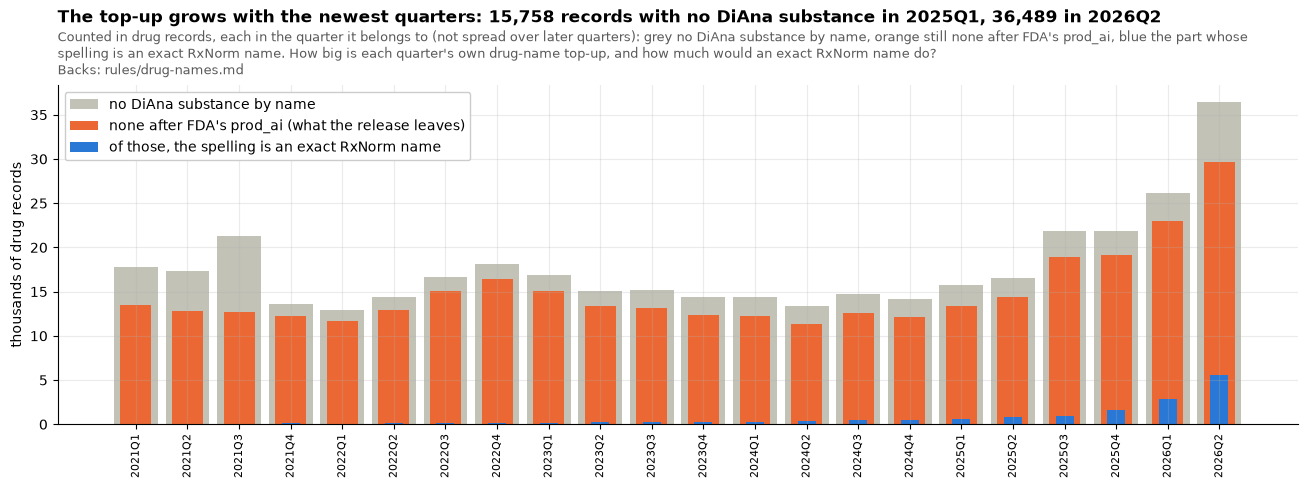

,quarter_T,records,unmapped_by_name,unmapped_after_prod_ai,rxnorm_exact_name,pct_rxnorm_recovers,new_spellings_reaching_5_records
0,2021q1,1629865,17805,13439,51,0.4,765
1,2021q2,1725567,17279,12800,71,0.6,622
2,2021q3,1685765,21332,12647,47,0.4,496
3,2021q4,1412743,13656,12216,92,0.8,1379
4,2022q1,1472574,12968,11729,65,0.6,677
5,2022q2,1244134,14337,12917,145,1.1,606
6,2022q3,1304486,16672,15051,135,0.9,599
7,2022q4,1359750,18096,16444,157,1.0,543
8,2023q1,1275742,16844,15115,136,0.9,393
9,2023q2,1303635,15110,13364,210,1.6,338


In [8]:
# each quarter's own unmapped drug records (counted in the quarter they belong to), and what an exact RxNorm name would recover
top = q("""SELECT r.quarter_T, count(*) AS records,
  count(*) FILTER (WHERE m.substance_T IS NULL) AS unmapped_by_name,
  count(*) FILTER (WHERE r.substance_source_T = 'none') AS unmapped_after_prod_ai,
  count(*) FILTER (WHERE r.substance_source_T = 'none' AND x.key_T IS NOT NULL) AS rxnorm_exact_name
FROM rec_T r LEFT JOIN spell_T s USING (drugname) LEFT JOIN diana_T m USING (key_T) LEFT JOIN rxname_T x ON x.key_T = s.key_T
WHERE r.quarter_T >= '2021q1' GROUP BY 1 ORDER BY 1""")
top["pct_rxnorm_recovers"] = (100 * top.rxnorm_exact_name / top.unmapped_after_prod_ai).round(1)
new5 = first.set_index("first_quarter").reached_5.reindex(top.quarter_T)
fig, ax = plt.subplots(figsize=(16, 4.4))
x = np.arange(len(top))
ax.bar(
    x, top.unmapped_by_name / 1e3, color=SERIES[7], width=0.85, label="no DiAna substance by name"
)
ax.bar(
    x,
    top.unmapped_after_prod_ai / 1e3,
    color=SERIES[1],
    width=0.6,
    label="none after FDA's prod_ai (what the release leaves)",
)
ax.bar(
    x,
    top.rxnorm_exact_name / 1e3,
    color=SERIES[0],
    width=0.35,
    label="of those, the spelling is an exact RxNorm name",
)
ax.set_ylabel("thousands of drug records")
t = top.set_index("quarter_T")
title(
    ax,
    f"The top-up grows with the newest quarters: {t.unmapped_by_name.get('2025q1', 0):,} records with no DiAna substance in 2025Q1, {t.unmapped_by_name.iloc[-1]:,} in {t.index[-1].upper()}",
    "Counted in drug records, each in the quarter it belongs to (not spread over later quarters): grey no DiAna substance by name, orange still none after FDA's prod_ai, "
    "blue the part whose spelling is an exact RxNorm name.",
    "How big is each quarter's own drug-name top-up, and how much would an exact RxNorm name do?",
    BACKS,
    width=190,
)
quarter_ticks(ax, top.quarter_T, every=1)
ax.legend(loc="upper left", framealpha=1)
plt.show()
top.assign(new_spellings_reaching_5_records=new5.values)

**What section 2 shows**, one item per chart:

- **The residue's long tail, and its kinds.** *Shows:* in drug records: DiAna gives no substance to 482,738 spellings carrying 1,150,308 records (1.55%); after FDA's `prod_ai`, 1,010,118 records stay without an ingredient (1.36%). 357,621 of the spellings are seen once and only 19 reach 200 records; the 37,606 seen 5 times or more hold half. By kind: a known name with extra words 29.3%, foreign brands and free text 29.2%, a combination written out 18.4%, a misspelling 14.2%, vague words 4.5% (never mappable), a newer drug RxNorm knows 2.0%, trial codes 1.4%, an FDA biosimilar suffix 0.1%. The most frequent unmapped spellings are new products: Zepbound KwikPen (2,539 records), Jascayd, Foundayo, Tryptyr, Ekterly, Zusduri. *Point:* about 64% of the residue is the kind reviewed rules can propose, an upper bound because the rules are rough (`insulin pump` counts as a known name with extra words); the rest needs a model or a person. *So what:* no quick win; ship as is (decision 5), then reviewed rules and model proposals by frequency, newest quarters first.
- **Each quarter's own top-up.** *Shows:* in drug records, each in its own quarter: records with no DiAna substance ran at 13,000 to 21,000 a quarter from 2021 to mid 2025, then rose from 15,758 in 2025Q1 to 36,489 in 2026Q2 (13,367 to 29,637 after FDA's `prod_ai`). An exact RxNorm name would recover 4.4% of 2025Q1's unmapped records and 18.9% of 2026Q2's. Since 2023, 140 to 390 new spellings a quarter reach 5 records. *Point:* the top-up is a small, steady review job that grows at the newest quarters, and RxNorm alone recovers little of it (Zepbound KwikPen needs the first-word rule). *So what:* our own quarterly top-up on each quarter's new spellings seen 5 times or more (decision 6), reviewed rules first (decision 5).

## 3 · Is DiAna a superset of RxNorm?

RxNorm is the US standard for naming drugs, and FDA's labels are keyed on its codes, so it decides how a drug finds its label.

**RxNorm source and its terms.** NLM's RxNorm Current Prescribable Content needs no UMLS licence. NLM's page ([prescribe.html](https://www.nlm.nih.gov/research/umls/rxnorm/docs/prescribe.html)) says: *"The National Library of Medicine provides this subset without any licensing restrictions. You do not need to log into the UMLS Terminology Services to access the subset."* and lists *"No license required; public domain"*. The subset is an approximation of the drugs currently marketed in the US: no obsolete drugs, no non-US drugs.

**The simple reference.** A spelling maps to RxNorm when its DiAna key equals, exactly, an RxNorm ingredient name (IN), precise ingredient such as a salt (PIN, taken to its ingredient), multiple-ingredient name (MIN) or brand name (BN, taken to its ingredients). No fuzzy matching, no strengths, no synonyms.

**Same ingredient.** RxNorm uses US names (USAN), DiAna international ones (INN). Two answers count as the same when they match after a short list of US and INN name pairs, the rule *-ic acid* = *-ate* (alendronic acid, alendronate), and ignoring spaces and hyphens. The pairs were picked from the most frequent disagreements and checked one by one; DiAna's vitamin letter names (vitamin b9 for folic acid) are a third convention, counted on their own.

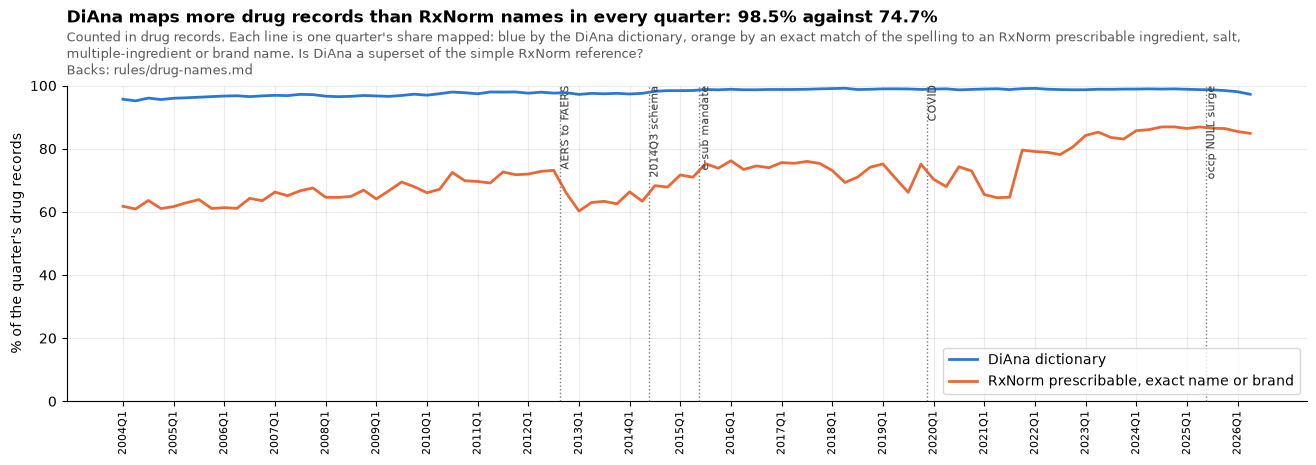

,value
drug_records,74375349.0
rxnorm_records,55557835.0
rxnorm_and_diana,55534042.0
rxnorm_only,23793.0
diana_only,17690999.0
rxnorm_spellings,7072.0
rxnorm_only_spellings,1056.0


In [9]:
rxcov = q("""SELECT r.quarter_T, 100.0 * avg((x.key_T IS NOT NULL)::INT) AS rxnorm_exact, 100.0 * avg((m.substance_T IS NOT NULL)::INT) AS diana
FROM rec_T r JOIN spell_T s USING (drugname) LEFT JOIN rxname_T x USING (key_T) LEFT JOIN diana_T m USING (key_T) GROUP BY 1 ORDER BY 1""")
rxtot = q("""SELECT sum(records_T) AS drug_records, sum(records_T) FILTER (WHERE x.key_T IS NOT NULL) AS rxnorm_records,
  sum(records_T) FILTER (WHERE x.key_T IS NOT NULL AND m.substance_T IS NOT NULL) AS rxnorm_and_diana,
  sum(records_T) FILTER (WHERE x.key_T IS NOT NULL AND m.substance_T IS NULL) AS rxnorm_only,
  sum(records_T) FILTER (WHERE x.key_T IS NULL AND m.substance_T IS NOT NULL) AS diana_only,
  count(DISTINCT key_T) FILTER (WHERE x.key_T IS NOT NULL) AS rxnorm_spellings,
  count(DISTINCT key_T) FILTER (WHERE x.key_T IS NOT NULL AND m.substance_T IS NULL) AS rxnorm_only_spellings
FROM spell_T s LEFT JOIN rxname_T x USING (key_T) LEFT JOIN diana_T m USING (key_T)""")
fig, ax = plt.subplots(figsize=(16, 4.1))
ax.plot(range(len(rxcov)), rxcov.diana, label="DiAna dictionary", color=SERIES[0])
ax.plot(
    range(len(rxcov)),
    rxcov.rxnorm_exact,
    label="RxNorm prescribable, exact name or brand",
    color=SERIES[1],
)
ax.set_ylim(0, 100)
ax.set_ylabel("% of the quarter's drug records")
t0 = rxtot.iloc[0]
title(
    ax,
    f"DiAna maps more drug records than RxNorm names in every quarter: {100 * (t0.rxnorm_and_diana + t0.diana_only) / t0.drug_records:.1f}% against {100 * t0.rxnorm_records / t0.drug_records:.1f}%",
    "Counted in drug records. Each line is one quarter's share mapped: blue by the DiAna dictionary, orange by an exact match of the spelling to an RxNorm "
    "prescribable ingredient, salt, multiple-ingredient or brand name.",
    "Is DiAna a superset of the simple RxNorm reference?",
    BACKS,
    width=185,
)
quarter_ticks(ax, rxcov.quarter_T)
mark_quarters(ax, rxcov.quarter_T)
ax.legend(loc="lower right")
plt.show()
rxtot.T.rename(columns={0: "value"})

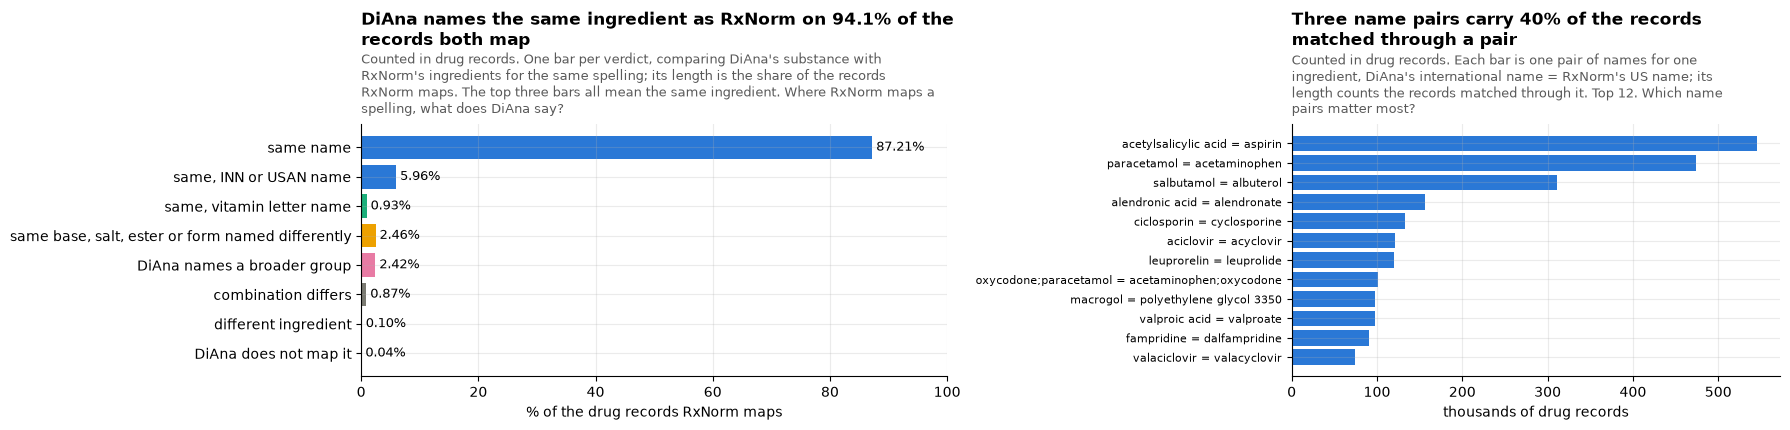

,spellings,drug_records,pct_of_rxnorm_records
verdict,,,
same name,4614,48453304.0,87.21
"same, INN or USAN name",373,3312585.0,5.96
"same, vitamin letter name",36,519453.0,0.93
"same base, salt, ester or form named differently",285,1367884.0,2.46
DiAna names a broader group,282,1343932.0,2.42
combination differs,225,483031.0,0.87
different ingredient,201,53853.0,0.10
DiAna does not map it,1056,23793.0,0.04


In [10]:
# USAN (or another US name) as RxNorm writes it -> INN as DiAna writes it. Both sides go through it.
USAN_INN = {
    "acetaminophen": "paracetamol",
    "aspirin": "acetylsalicylic acid",
    "albuterol": "salbutamol",
    "levalbuterol": "levosalbutamol",
    "cyclosporine": "ciclosporin",
    "acyclovir": "aciclovir",
    "valacyclovir": "valaciclovir",
    "leuprolide": "leuprorelin",
    "mesalamine": "mesalazine",
    "nitroglycerin": "glyceryl trinitrate",
    "dalfampridine": "fampridine",
    "torsemide": "torasemide",
    "glyburide": "glibenclamide",
    "hydroxyurea": "hydroxycarbamide",
    "cephalexin": "cefalexin",
    "dicyclomine": "dicycloverine",
    "beclomethasone": "beclometasone",
    "meclizine": "meclozine",
    "rifampin": "rifampicin",
    "indomethacin": "indometacin",
    "chlorpheniramine": "chlorphenamine",
    "chlorthalidone": "chlortalidone",
    "meperidine": "pethidine",
    "methamphetamine": "metamfetamine",
    "amphetamine": "amfetamine",
    "dextroamphetamine": "dexamfetamine",
    "benztropine": "benzatropine",
    "methimazole": "thiamazole",
    "dipyrone": "metamizole",
    "calcipotriene": "calcipotriol",
    "norethindrone": "norethisterone",
    "penicillin v": "phenoxymethylpenicillin",
    "penicillin g": "benzylpenicillin",
    "carbocysteine": "carbocisteine",
    "cromolyn": "cromoglicic acid",
    "succinylcholine": "suxamethonium",
    "simethicone": "simeticone",
    "polyethylene glycol 3350": "macrogol",
    "polyethylene glycol 4000": "macrogol",
    "polyethylene glycols": "macrogol",
    "leucovorin": "folinic acid",
    "levoleucovorin": "levofolinic acid",
    "isopropyl alcohol": "isopropanol",
    "aluminum": "aluminium",
    "cholecalciferol": "colecalciferol",
    "epinephrine": "adrenaline",
    "norepinephrine": "noradrenaline",
    "clomiphene": "clomifene",
    "ethinyl estradiol": "ethinylestradiol",
    "c1 esterase inhibitor": "c1-inhibitor",
    "glutamine": "levoglutamide",
    "cholestyramine resin": "colestyramine",
    "chorionic gonadotropin": "chorionic gonadotrophin",
    "mechlorethamine": "chlormethine",
    "glycerin": "glycerol",
    "thioguanine": "tioguanine",
    "flumethasone": "flumetasone",
    "dichlorphenamide": "diclofenamide",
    "cysteamine": "mercaptamine",
    "halobetasol": "ulobetasol",
    "methylene blue": "methylthioninium",
    "tetrahydrozoline": "tetryzoline",
    "proparacaine": "proxymetacaine",
    "methylergonovine": "methylergometrine",
    "activated charcoal": "charcoal, activated",
    "rho(d) immune globulin": "anti-d immunoglobulin",
    "mineral oil": "paraffin",
    "tapinarof": "benvitimod",
}
# DiAna's vitamin letter names, a third convention
VITAMINS = {
    "vitamin b9": "folic acid",
    "vitamin d3": "colecalciferol",
    "vitamin c": "ascorbic acid",
    "vitamin b1": "thiamine",
    "vitamin b3": "niacin",
    "vitamin b6": "pyridoxine",
    "vitamin b7": "biotin",
    "vitamin d2": "ergocalciferol",
    "vitamin b2": "riboflavin",
    "vitamin b12": "cyanocobalamin",
    "vitamin b5": "pantothenic acid",
    "vitamin k1": "phytonadione",
}
BROAD = {
    "insulin",
    "iron",
    "botulinum toxin",
    "factor viii",
    "factor ix",
    "unsaturated fatty acids",
    "multienzymes",
    "artificial tears",
    "skin care",
}


def canon(name, vitamins=False):
    """One ingredient name in a comparable form: US name to INN, -ic acid to -ate, no spaces or hyphens."""
    n = USAN_INN.get(name, name)
    if vitamins:
        n = VITAMINS.get(n, n)
    n = re.sub(r"a?ic acid$", "ate", n)
    return re.sub(r"[\s-]", "", n)


def same(diana, rx, vitamins=False):
    return sorted(canon(c, vitamins) for c in diana.split(";")) == sorted(
        canon(c, vitamins) for c in rx.split(";")
    )


def compare(diana, rx):
    """How DiAna's substance relates to RxNorm's ingredients for one spelling."""
    if not isinstance(diana, str):
        return "DiAna does not map it"
    if diana == rx:
        return "same name"
    if same(diana, rx):
        return "same, INN or USAN name"
    if same(diana, rx, vitamins=True):
        return "same, vitamin letter name"
    if ";" in diana or ";" in rx:
        return "combination differs"
    if (
        "unspecified" in diana
        or diana.endswith((" spp", "vaccine"))
        or diana.startswith("vitamin")
        or diana in BROAD
    ):
        return "DiAna names a broader group"
    d, r = canon(diana), canon(rx)
    if d in r or r in d:
        return "same base, salt, ester or form named differently"
    return "different ingredient"


both = q("""SELECT s.key_T, sum(s.records_T) AS records_T, any_value(m.substance_T) AS diana, any_value(x.rx_ingredients_T) AS rxnorm
FROM spell_T s JOIN rxname_T x USING (key_T) LEFT JOIN diana_T m USING (key_T) GROUP BY 1 ORDER BY 2 DESC, 1""")
both["verdict"] = [compare(d, r) for d, r in zip(both.diana, both.rxnorm, strict=True)]
order = [
    "same name",
    "same, INN or USAN name",
    "same, vitamin letter name",
    "same base, salt, ester or form named differently",
    "DiAna names a broader group",
    "combination differs",
    "different ingredient",
    "DiAna does not map it",
]
verdict = (
    both.groupby("verdict")
    .agg(spellings=("key_T", "size"), drug_records=("records_T", "sum"))
    .reindex(order)
    .fillna(0)
)
verdict["pct_of_rxnorm_records"] = (100 * verdict.drug_records / verdict.drug_records.sum()).round(
    2
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
cols = [SERIES[0], SERIES[0], SERIES[2], SERIES[3], SERIES[4], SERIES[6], SERIES[1], SERIES[7]]
a1.barh(verdict.index[::-1], verdict.pct_of_rxnorm_records[::-1], color=cols[::-1])
for yy, v in enumerate(verdict.pct_of_rxnorm_records[::-1]):
    a1.text(v, yy, f" {v:.2f}%", va="center", fontsize=9)
a1.set_xlim(0, 100)
a1.set_xlabel("% of the drug records RxNorm maps")
same_pct = 100 * verdict.loc[order[:3], "drug_records"].sum() / verdict.drug_records.sum()
title(
    a1,
    f"DiAna names the same ingredient as RxNorm on {same_pct:.1f}% of the records both map",
    "Counted in drug records. One bar per verdict, comparing DiAna's substance with RxNorm's ingredients for the same spelling; its length is the share of the records "
    "RxNorm maps. The top three bars all mean the same ingredient.",
    "Where RxNorm maps a spelling, what does DiAna say?",
    width=85,
)
used = (
    both[both.verdict == "same, INN or USAN name"]
    .assign(pair=lambda d: d.diana + " = " + d.rxnorm)
    .groupby("pair")
    .records_T.sum()
    .nlargest(12)
)
a2.barh(used.index[::-1], used.values[::-1] / 1e3, color=SERIES[0])
a2.set_xlabel("thousands of drug records")
share3 = (
    100
    * used.iloc[:3].sum()
    / both.loc[both.verdict == "same, INN or USAN name", "records_T"].sum()
)
title(
    a2,
    f"Three name pairs carry {share3:.0f}% of the records matched through a pair",
    "Counted in drug records. Each bar is one pair of names for one ingredient, DiAna's international name = RxNorm's US name; its length counts the records "
    "matched through it. Top 12.",
    "Which name pairs matter most?",
    width=68,
)
a2.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
verdict

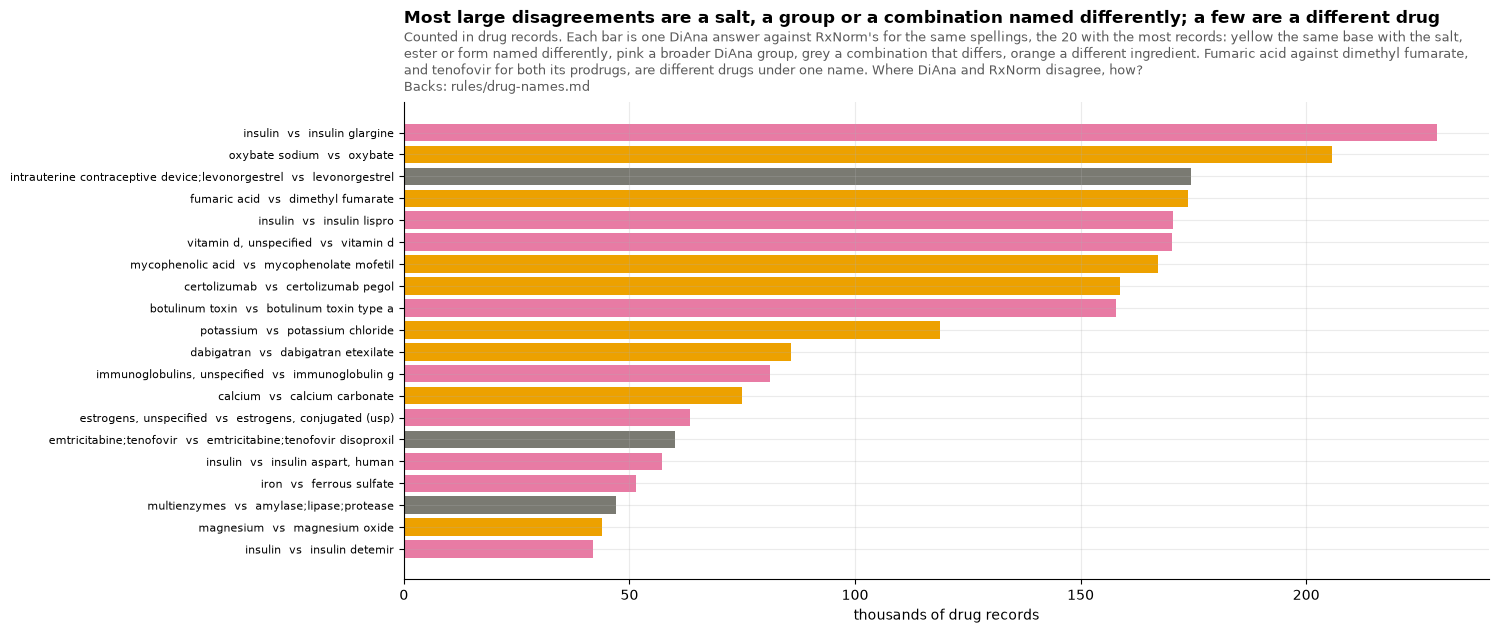

,verdict,diana,rxnorm,drug_records,spellings,example
402,different ingredient,antithymocyte immunoglobulin,"lymphocyte immune globulin, anti-thymocyte globulin",10713.0,2,thymoglobulin
416,different ingredient,conestat alfa,c1 esterase inhibitor,8672.0,1,ruconest
456,different ingredient,isavuconazole,isavuconazonium,4766.0,3,cresemba
531,different ingredient,xantofyl,lutein,4603.0,1,lutein
476,different ingredient,ostilodrostat,osilodrostat,3729.0,1,isturisa
433,different ingredient,factor viii inhibitor bypassing fraction,anti-inhibitor coagulant complex,2025.0,2,feiba
517,different ingredient,talimogene laherparepvec,"herpesvirus 1, human",2015.0,2,imlygic
455,different ingredient,iodine,potassium iodide,1431.0,2,potassium iodide
395,different ingredient,aluminium,aluminum hydroxide,1003.0,2,aluminum hydroxide
509,different ingredient,simeticone,dimethicone,769.0,3,dimethicone


,verdict,diana,rxnorm,drug_records,spellings,example
71,DiAna names a broader group,insulin,insulin glargine,229030.0,6,lantus
632,"same base, salt, ester or form named differently",oxybate sodium,oxybate,205621.0,5,xyrem
326,combination differs,intrauterine contraceptive device;levonorgestrel,levonorgestrel,174538.0,3,mirena
590,"same base, salt, ester or form named differently",fumaric acid,dimethyl fumarate,173871.0,2,tecfidera
74,DiAna names a broader group,insulin,insulin lispro,170573.0,5,humalog
182,DiAna names a broader group,"vitamin d, unspecified",vitamin d,170164.0,1,vitamin d
628,"same base, salt, ester or form named differently",mycophenolic acid,mycophenolate mofetil,167220.0,3,mycophenolate mofetil
567,"same base, salt, ester or form named differently",certolizumab,certolizumab pegol,158718.0,2,cimzia
22,DiAna names a broader group,botulinum toxin,botulinum toxin type a,157807.0,10,botox cosmetic
645,"same base, salt, ester or form named differently",potassium,potassium chloride,118760.0,2,potassium chloride


In [11]:
dis = (
    both[
        both.verdict.isin(
            [
                "same base, salt, ester or form named differently",
                "DiAna names a broader group",
                "combination differs",
                "different ingredient",
            ]
        )
    ]
    .groupby(["verdict", "diana", "rxnorm"])
    .agg(drug_records=("records_T", "sum"), spellings=("key_T", "size"), example=("key_T", "first"))
    .reset_index()
    .sort_values("drug_records", ascending=False)
)
top20 = dis.head(20)
fig, ax = plt.subplots(figsize=(14, 6.2))
ax.barh(
    [f"{d}  vs  {r}"[:70] for d, r in zip(top20.diana[::-1], top20.rxnorm[::-1], strict=True)],
    top20.drug_records[::-1] / 1e3,
    color=[
        {
            "same base, salt, ester or form named differently": SERIES[3],
            "DiAna names a broader group": SERIES[4],
            "combination differs": SERIES[6],
            "different ingredient": SERIES[1],
        }[v]
        for v in top20.verdict[::-1]
    ],
)
ax.set_xlabel("thousands of drug records")
title(
    ax,
    "Most large disagreements are a salt, a group or a combination named differently; a few are a different drug",
    "Counted in drug records. Each bar is one DiAna answer against RxNorm's for the same spellings, the 20 with the most records: yellow the same base with the salt, "
    "ester or form named differently, pink a broader DiAna group, grey a combination that differs, orange a different ingredient. Fumaric acid against "
    "dimethyl fumarate, and tenofovir for both its prodrugs, are different drugs under one name.",
    "Where DiAna and RxNorm disagree, how?",
    BACKS,
    width=165,
)
ax.tick_params(axis="y", labelsize=8)
plt.show()
display(dis[dis.verdict == "different ingredient"].head(15))
dis.head(30)

1854704250.py:59: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


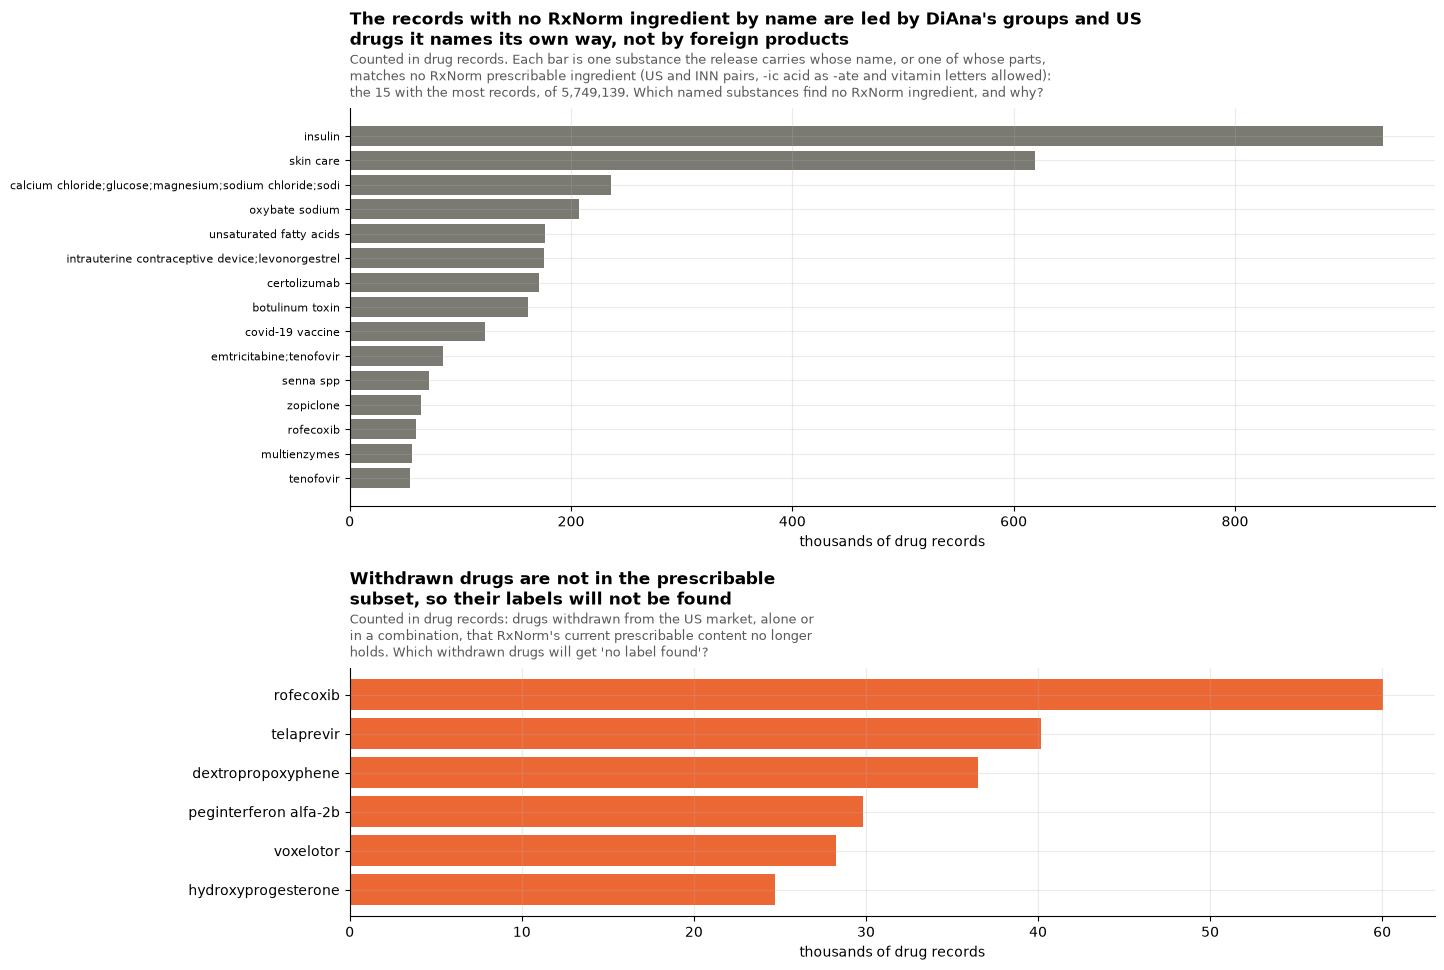

named substances carried: 71,929,599 records; whose every part has an RxNorm ingredient by name: 66,180,460 (92.0%, an upper bound: electrolytes match as their element)
no RxNorm ingredient by name: 5,749,139 records; of those the spelling itself is an exact RxNorm name in 1,882,931 (33%), which the spelling's own match recovers


withdrawn
rofecoxib                60050
telaprevir               40164
dextropropoxyphene       36509
peginterferon alfa-2b    29836
voxelotor                28258
hydroxyprogesterone      24690
Name: drug records, dtype: int64

,substance_T,records,spelling_exact_in_rxnorm,codeable
10454,insulin,933812,584069,False
3607,skin care,619519,2502,False
10527,calcium chloride;glucose;magnesium;sodium chloride;sodium lactate,236279,0,False
197,oxybate sodium,207118,205621,False
5653,unsaturated fatty acids,176157,32606,False
75,intrauterine contraceptive device;levonorgestrel,175482,174538,False
5593,certolizumab,171383,158718,False
3659,botulinum toxin,161114,158170,False
11366,covid-19 vaccine,122299,0,False
3485,emtricitabine;tenofovir,84419,71420,False


In [12]:
# the substances the release carries (our corrections applied) that find no RxNorm ingredient by name, and why
rx_in = q(f"""SELECT DISTINCT lower(column14) AS nm FROM read_csv('{RX_CONSO}', delim='|', header=false, quote='', escape='', all_varchar=true)
              WHERE column11 = 'RXNORM' AND column12 = 'IN' AND column16 = 'N'""").nm
rx_canon = {canon(n, vitamins=True) for n in rx_in}
subs = q("""SELECT r.substance_T, count(*) AS records, count(*) FILTER (WHERE x.key_T IS NOT NULL) AS spelling_exact_in_rxnorm
FROM rec_T r LEFT JOIN spell_T s USING (drugname) LEFT JOIN rxname_T x ON x.key_T = s.key_T
WHERE r.substance_T IS NOT NULL AND r.substance_T NOT LIKE '%unspecified%' AND r.substance_T NOT IN ('no medication', 'no drug') GROUP BY 1""")
subs["codeable"] = [
    all(canon(c, vitamins=True) in rx_canon for c in s.split(";")) for s in subs.substance_T
]
named = subs.records.sum()
nocode = subs[~subs.codeable]
WITHDRAWN = [
    "rofecoxib",
    "telaprevir",
    "peginterferon alfa-2b",
    "voxelotor",
    "hydroxyprogesterone",
    "dextropropoxyphene",
]
gone = (
    subs[subs.substance_T.apply(lambda s: any(p in WITHDRAWN for p in s.split(";")))]
    .assign(
        withdrawn=lambda d: d.substance_T.apply(
            lambda s: next(p for p in s.split(";") if p in WITHDRAWN)
        )
    )
    .groupby("withdrawn")
    .records.sum()
    .reindex(WITHDRAWN)
    .fillna(0)
    .astype(int)
    .sort_values(ascending=False)
)
topn = nocode.nlargest(15, "records")
fig, (a1, a2) = plt.subplots(
    2, 1, figsize=(14, 10.5), gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.5}
)
a1.barh(topn.substance_T.str[:55][::-1], topn.records[::-1] / 1e3, color=SERIES[6])
a1.set_xlabel("thousands of drug records")
title(
    a1,
    "The records with no RxNorm ingredient by name are led by DiAna's groups and US drugs it names its own way, not by foreign products",
    f"Counted in drug records. Each bar is one substance the release carries whose name, or one of whose parts, matches no RxNorm prescribable ingredient "
    f"(US and INN pairs, -ic acid as -ate and vitamin letters allowed): the 15 with the most records, of {nocode.records.sum():,}.",
    "Which named substances find no RxNorm ingredient, and why?",
    width=110,
)
a1.tick_params(axis="y", labelsize=8)
a2.barh(gone.index[::-1], gone.values[::-1] / 1e3, color=SERIES[1])
a2.set_xlabel("thousands of drug records")
title(
    a2,
    "Withdrawn drugs are not in the prescribable subset, so their labels will not be found",
    "Counted in drug records: drugs withdrawn from the US market, alone or in a combination, that RxNorm's current prescribable content no longer holds.",
    "Which withdrawn drugs will get 'no label found'?",
    width=70,
)
plt.tight_layout()
plt.show()
print(
    f"named substances carried: {named:,} records; whose every part has an RxNorm ingredient by name: {subs[subs.codeable].records.sum():,} "
    f"({100 * subs[subs.codeable].records.sum() / named:.1f}%, an upper bound: electrolytes match as their element)"
)
print(
    f"no RxNorm ingredient by name: {nocode.records.sum():,} records; of those the spelling itself is an exact RxNorm name in "
    f"{nocode.spelling_exact_in_rxnorm.sum():,} ({100 * nocode.spelling_exact_in_rxnorm.sum() / nocode.records.sum():.0f}%), which the spelling's own match recovers"
)
display(gone.rename("drug records"))
topn

**What section 3 shows**, one item per chart:

- **DiAna against an exact RxNorm name, by quarter.** *Shows:* in drug records: an exact RxNorm name maps 74.7%, DiAna 98.5%, and DiAna maps all but 23,793 of the records RxNorm names (1,056 spellings, mostly newer US brands, of the 7,072 that match RxNorm exactly). *Point:* on coverage, DiAna is a superset of the simple RxNorm reference. *So what:* DiAna is the seed (decision 1); the RxNorm-only records are DiAna's lag, which the spelling's own RxNorm match covers (decision 2).
- **Agreement where both map.** *Shows:* in drug records: the same ingredient on 94.1% of the records both map (87.21% the same name, 5.96% the INN for RxNorm's US name, 0.93% a vitamin letter name); 2.46% a salt, ester or form named differently, 2.42% a broader DiAna group, 0.87% a combination that differs, 0.10% a different ingredient. Three name pairs carry 40% of the records matched through a pair. *Point:* DiAna and RxNorm mostly name the same thing differently. *So what:* RxNorm codes beside the DiAna name, a later step, through a short reviewed list of INN-to-US name pairs (decision 2). The 94.1% leans on a pair list picked from the most frequent disagreements.
- **The largest disagreements.** *Shows:* insulin against insulin glargine and lispro, oxybate sodium, Mirena's added device part, fumaric acid against dimethyl fumarate (Tecfidera), mycophenolic acid against mycophenolate mofetil, certolizumab, botulinum toxin. Real errors are few: Cartia as aspirin where the US Cartia XT is diltiazem, Isturisa as `ostilodrostat`. *Point:* most disagreements are naming, but two are different drugs under one name: fumaric acid for dimethyl fumarate, and one `tenofovir` for tenofovir disoproxil (Truvada) and tenofovir alafenamide (Descovy), whose kidney and bone safety differ. *So what:* fumaric acid, Cartia and Isturisa are corrected (section 6, decision 7); insulin and tenofovir stay grouped for counting, and their RxNorm codes carry the precise ingredient (decision 7).
- **Named substances with no RxNorm ingredient by name, and withdrawn drugs.** *Shows:* in drug records, on the substances the release carries (our corrections applied): of 71.9 million records with a named substance, 92.0% could take an RxNorm ingredient by name, an upper bound because electrolytes match as their element. The 5.75 million that cannot are led by DiAna's own groups and US drugs it names its own way, not by foreign products: insulin 933,812, skin care 619,519, the Dianeal solutions 236,279, oxybate sodium 207,118, unsaturated fatty acids 176,157, Mirena 175,482, certolizumab 171,383, botulinum toxin 161,114, covid-19 vaccine 122,299, emtricitabine with tenofovir 84,419. The spelling's own exact RxNorm match recovers 1.88 million of them (33%). Drugs withdrawn from the US market are not in the prescribable subset: rofecoxib 60,050 records, telaprevir 40,164, dextropropoxyphene 36,509, peginterferon alfa-2b 29,836, voxelotor 28,258, hydroxyprogesterone 24,690. *Point:* the uncoded rest is mostly naming and grouping, plus withdrawn drugs, and only partly foreign products and herbals. *So what:* the spelling's own exact RxNorm match first, DiAna's name second (decision 2); a withdrawn drug's record will show "no label found", and the methods page says so.

## 4 · A product, as a user would look for it

How one medicine spreads across FDA's spellings, and how much a count changes with the roles counted. Three cases: one brand with many biosimilars (**adalimumab**), one combination (**sacubitril;valsartan**, Entresto), and one brand whose US composition changed (**Zantac**: ranitidine until the 2020 recall, famotidine as *Zantac 360* since 2021). Cases are the default case set; a suspect is PS or SS.

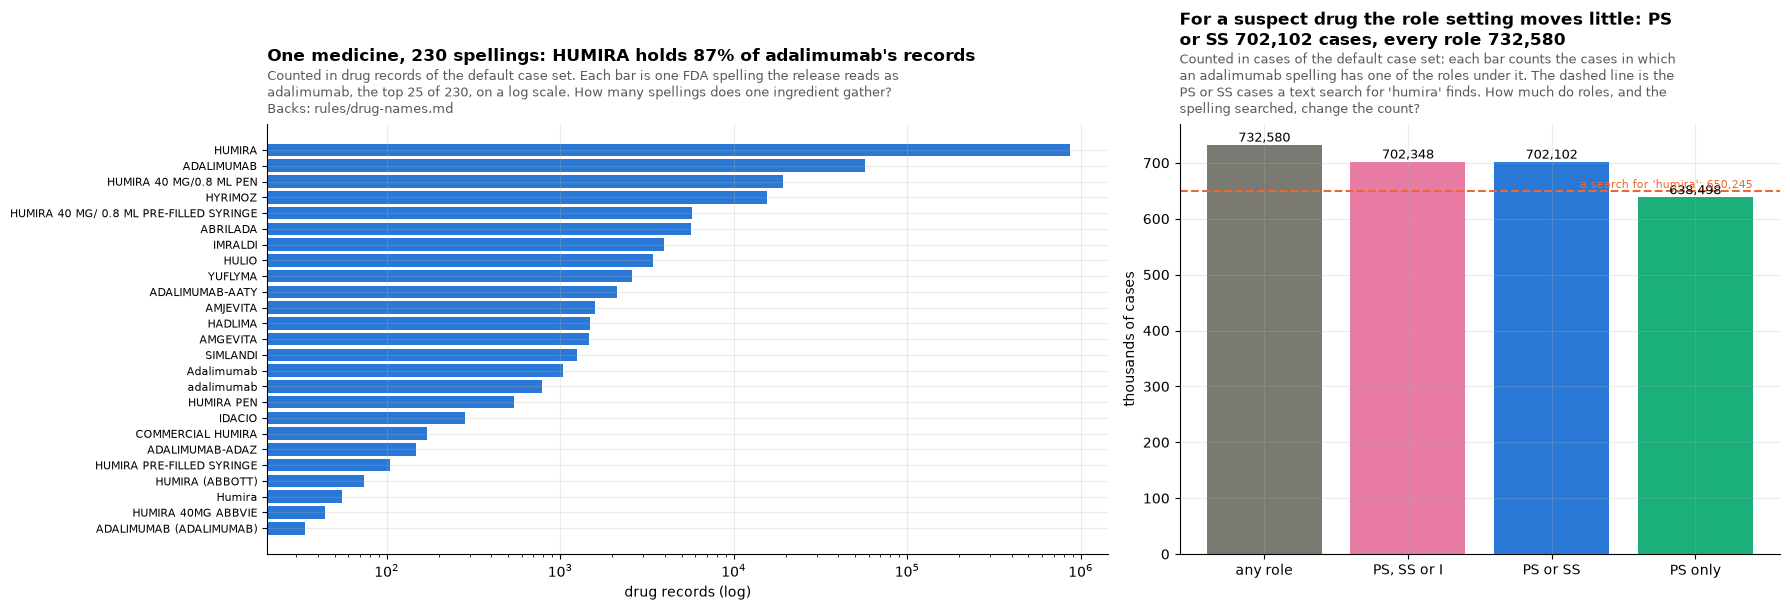

a text search for 'humira' finds 650,245 of the 702,102 cases with adalimumab as PS or SS
168 spellings look like adalimumab but DiAna does not map them: 781 drug records


,spelling,drug_records,first_seen
0,cyltezo,144,2023q3
1,yusimry,107,2023q4
2,adalimumab-adbm,73,2024q1
3,adalimumab-aacf,64,2024q1
4,adalimumab-ryvk,38,2024q3
5,adalimumab-aqvh,22,2023q3
6,humira (adalimumab) open label,15,2013q1
7,adalimumab ryvk,12,2025q2
8,hadlima [adalimumab bwwd,11,2025q1
9,adalimumab adbm,10,2024q4


,fda_spelling,drug_records,PS,SS,C,I
0,HUMIRA,864096,577340,257177,29236,343
1,ADALIMUMAB,56988,20016,31293,5628,51
2,HUMIRA 40 MG/0.8 ML PEN,19192,15421,3767,3,1
3,HYRIMOZ,15529,5884,8456,1185,4
4,HUMIRA 40 MG/ 0.8 ML PRE-FILLED SYRINGE,5750,4738,1012,0,0
5,ABRILADA,5647,2204,3161,282,0
6,IMRALDI,3981,2538,1350,77,16
7,HULIO,3446,1537,1767,139,3
8,YUFLYMA,2593,1506,1050,35,2
9,ADALIMUMAB-AATY,2111,1360,748,3,0


In [13]:
# cases are the default case set (probable duplicates left out); suspect means FDA's PS or SS
con.execute("""CREATE TEMP TABLE ex_T AS
SELECT r.case_key_T, r.quarter_T, r.role_cod, r.drugname, s.key_T, r.substance_T
FROM rec_T r JOIN spell_T s USING (drugname)
WHERE r.dup_kept_T AND (list_contains(string_split(r.substance_T, ';'), 'adalimumab') OR list_contains(string_split(r.substance_T, ';'), 'valsartan')
   OR r.substance_T IN ('ranitidine', 'famotidine') OR s.key_T LIKE '%zantac%'
   OR regexp_matches(s.key_T, 'humira|adalim|amjevita|amgevita|cyltezo|hadlima|hulio|hyrimoz|idacio|yuflyma|yusimry|simlandi|abrilada|imraldi'))""")
ada = q("""SELECT drugname AS fda_spelling, count(*) AS drug_records,
  count(*) FILTER (WHERE role_cod = 'PS') AS PS, count(*) FILTER (WHERE role_cod = 'SS') AS SS,
  count(*) FILTER (WHERE role_cod = 'C') AS C, count(*) FILTER (WHERE role_cod = 'I') AS I
FROM ex_T WHERE substance_T = 'adalimumab' GROUP BY 1 ORDER BY 2 DESC, 1""")


def cases(where):
    return q(f"""SELECT count(DISTINCT case_key_T) AS any_role,
      count(DISTINCT case_key_T) FILTER (WHERE role_cod IN ('PS', 'SS', 'I')) AS ps_ss_or_i,
      count(DISTINCT case_key_T) FILTER (WHERE role_cod IN ('PS', 'SS')) AS ps_or_ss,
      count(DISTINCT case_key_T) FILTER (WHERE role_cod = 'PS') AS ps_only FROM ex_T WHERE {where}""").iloc[
        0
    ]


ada_cases = cases("substance_T = 'adalimumab'")
humira_text = q("""SELECT count(DISTINCT case_key_T) AS n FROM ex_T
    WHERE substance_T = 'adalimumab' AND contains(upper(drugname), 'HUMIRA') AND role_cod IN ('PS', 'SS')""").n[
    0
]
missed = q("""SELECT key_T AS spelling, count(*) AS drug_records, min(quarter_T) AS first_seen FROM ex_T
WHERE substance_T IS NULL AND regexp_matches(key_T, 'humira|adalim|amjevita|amgevita|cyltezo|hadlima|hulio|hyrimoz|idacio|yuflyma|yusimry|simlandi|abrilada|imraldi')
GROUP BY 1 ORDER BY 2 DESC, 1""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1.4, 1]})
t = ada.head(25)
a1.barh(t.fda_spelling[::-1].str[:45], t.drug_records[::-1], color=SERIES[0])
a1.set_xscale("log")
a1.set_xlabel("drug records (log)")
title(
    a1,
    f"One medicine, {len(ada)} spellings: {ada.fda_spelling.iloc[0]} holds {100 * ada.drug_records.iloc[0] / ada.drug_records.sum():.0f}% of adalimumab's records",
    f"Counted in drug records of the default case set. Each bar is one FDA spelling the release reads as adalimumab, the top 25 of {len(ada)}, on a log scale.",
    "How many spellings does one ingredient gather?",
    BACKS,
    width=107,
)
a1.tick_params(axis="y", labelsize=8)
labels = ["any role", "PS, SS or I", "PS or SS", "PS only"]
a2.bar(labels, ada_cases.values / 1e3, color=[SERIES[6], SERIES[4], SERIES[0], SERIES[2]])
for xx, v in enumerate(ada_cases.values):
    a2.text(xx, v / 1e3, f"{v:,}", ha="center", va="bottom", fontsize=9)
a2.axhline(humira_text / 1e3, color=SERIES[1], ls="--", lw=1.5)
a2.text(
    3.4,
    humira_text / 1e3,
    f" a search for 'humira': {humira_text:,}",
    color=SERIES[1],
    fontsize=8,
    va="bottom",
    ha="right",
)
a2.set_ylabel("thousands of cases")
title(
    a2,
    f"For a suspect drug the role setting moves little: PS or SS {ada_cases.ps_or_ss:,} cases, every role {ada_cases.any_role:,}",
    "Counted in cases of the default case set: each bar counts the cases in which an adalimumab spelling has one of the roles under it. "
    "The dashed line is the PS or SS cases a text search for 'humira' finds.",
    "How much do roles, and the spelling searched, change the count?",
    width=76,
)
plt.tight_layout()
plt.show()
print(
    f"a text search for 'humira' finds {humira_text:,} of the {ada_cases.ps_or_ss:,} cases with adalimumab as PS or SS"
)
print(
    f"{len(missed)} spellings look like adalimumab but DiAna does not map them: {int(missed.drug_records.sum()):,} drug records"
)
display(missed.head(12))
ada.head(30)

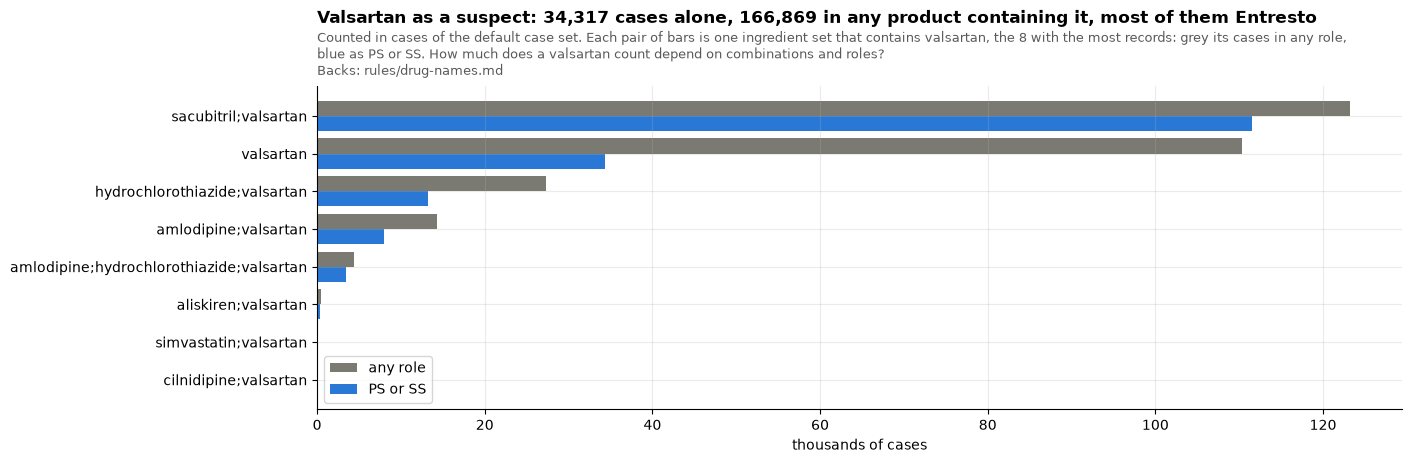

cases with valsartan in any product: {'any_role': 274054, 'ps_ss_or_i': 167803, 'ps_or_ss': 166869, 'ps_only': 150002}


,substance_set,drug_records,fda_spellings,cases_any_role,cases_ps_ss
0,sacubitril;valsartan,151439,105,123267,111479
1,valsartan,124017,1146,110324,34317
2,hydrochlorothiazide;valsartan,32253,926,27338,13247
3,amlodipine;valsartan,16244,271,14320,8011
4,amlodipine;hydrochlorothiazide;valsartan,5363,79,4356,3395
5,aliskiren;valsartan,490,9,460,314
6,simvastatin;valsartan,61,5,53,51
7,cilnidipine;valsartan,53,4,51,0
8,lercanidipine;valsartan,8,2,7,1
9,nebivolol;valsartan,8,1,8,5


,fda_spelling,drug_records
0,ENTRESTO,138993
1,SACUBITRIL\VALSARTAN,6865
2,VYMADA,2698
3,UPERIO,596
4,LCZ696,429
5,"SACUBITRIL,VALSARTAN",307
6,BLINDED LCZ696,253
7,SACUBITRIL/VALSARTAN,239
8,SACUBITRIL W/VALSARTAN,218
9,SACUBITRIL VALSARTAN SODIUM HYDRATE,168


In [14]:
val = q("""SELECT substance_T AS substance_set, count(*) AS drug_records, count(DISTINCT drugname) AS fda_spellings,
  count(DISTINCT case_key_T) AS cases_any_role, count(DISTINCT case_key_T) FILTER (WHERE role_cod IN ('PS', 'SS')) AS cases_ps_ss
FROM ex_T WHERE list_contains(string_split(substance_T, ';'), 'valsartan') GROUP BY 1 ORDER BY 2 DESC""")
ent = q(
    """SELECT drugname AS fda_spelling, count(*) AS drug_records FROM ex_T WHERE substance_T = 'sacubitril;valsartan' GROUP BY 1 ORDER BY 2 DESC, 1 LIMIT 12"""
)
anyv = cases("list_contains(string_split(substance_T, ';'), 'valsartan')")
fig, ax = plt.subplots(figsize=(14, 4.2))
tv = val.head(8)
y = np.arange(len(tv))
ax.barh(y - 0.2, tv.cases_any_role / 1e3, 0.4, label="any role", color=SERIES[6])
ax.barh(y + 0.2, tv.cases_ps_ss / 1e3, 0.4, label="PS or SS", color=SERIES[0])
ax.set_yticks(y)
ax.set_yticklabels(tv.substance_set)
ax.invert_yaxis()
ax.set_xlabel("thousands of cases")
vs = val.set_index("substance_set").cases_ps_ss
title(
    ax,
    f"Valsartan as a suspect: {vs['valsartan']:,} cases alone, {anyv.ps_or_ss:,} in any product containing it, most of them Entresto",
    "Counted in cases of the default case set. Each pair of bars is one ingredient set that contains valsartan, the 8 with the most records: grey its cases in any role, blue as PS or SS.",
    "How much does a valsartan count depend on combinations and roles?",
    BACKS,
    width=163,
)
ax.legend()
plt.show()
print("cases with valsartan in any product:", {k: int(v) for k, v in anyv.items()})
display(val)
ent

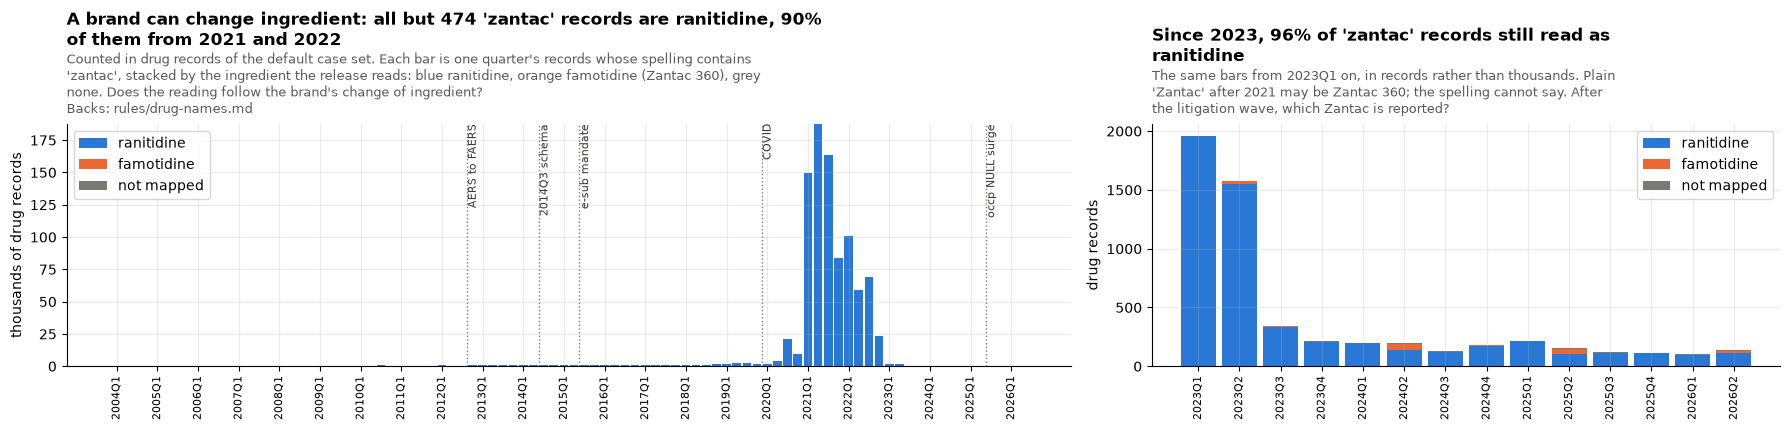

,ingredient,cases_any_role,cases_ps_ss
0,ranitidine,502907,399823
1,famotidine,124199,11659


,fda_spelling,ingredient,drug_records,first_seen,last_seen
0,ZANTAC,ranitidine,915482,2004q1,2026q2
1,ZANTAC 150,ranitidine,2953,2004q1,2013q4
2,ZANTAC 75,ranitidine,2934,2004q1,2026q2
3,ZANTAC 150 (RANITIDINE HYDROCHLORIDE),ranitidine,1957,2012q4,2024q3
4,ZANTAC (RANITIDINE HYDROCHLORIDE),ranitidine,745,2012q4,2014q2
5,AZANTAC,ranitidine,619,2004q4,2021q3
6,Zantac,ranitidine,322,2012q4,2017q3
7,ZANTAC 75 (OTC),ranitidine,241,2018q2,2023q2
8,ZANTAC 360,famotidine,212,2021q2,2026q2
9,ZANTAC MAXIMUM STRENGTH 150 COOL MINT,ranitidine,210,2014q3,2020q2


In [15]:
z = q(
    """SELECT quarter_T, coalesce(substance_T, 'not mapped') AS substance, count(*) AS n FROM ex_T WHERE key_T LIKE '%zantac%' GROUP BY ALL ORDER BY 1"""
)
zp = z.pivot(index="quarter_T", columns="substance", values="n").fillna(0)
for c in ["ranitidine", "famotidine", "not mapped"]:
    if c not in zp:
        zp[c] = 0
zp = zp[["ranitidine", "famotidine", "not mapped"]]
zs = q("""SELECT drugname AS fda_spelling, coalesce(substance_T, 'not mapped') AS ingredient, count(*) AS drug_records, min(quarter_T) AS first_seen, max(quarter_T) AS last_seen
FROM ex_T WHERE key_T LIKE '%zantac%' GROUP BY 1, 2 ORDER BY 3 DESC, 1""")
rf = q("""SELECT substance_T AS ingredient, count(DISTINCT case_key_T) AS cases_any_role, count(DISTINCT case_key_T) FILTER (WHERE role_cod IN ('PS', 'SS')) AS cases_ps_ss
FROM ex_T WHERE substance_T IN ('ranitidine', 'famotidine') GROUP BY 1""")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(zp))
for c, col in zip(zp.columns, [SERIES[0], SERIES[1], SERIES[6]], strict=True):
    a1.bar(range(len(zp)), zp[c] / 1e3, bottom=bottom, color=col, label=c, width=0.85)
    bottom += zp[c].values / 1e3
a1.set_ylabel("thousands of drug records")
wave = 100 * zp.loc[(zp.index >= "2021q1") & (zp.index <= "2022q4")].values.sum() / zp.values.sum()
title(
    a1,
    f"A brand can change ingredient: all but {int(zp.values.sum() - zp.ranitidine.sum()):,} 'zantac' records are ranitidine, {wave:.0f}% of them from 2021 and 2022",
    "Counted in drug records of the default case set. Each bar is one quarter's records whose spelling contains 'zantac', stacked by the ingredient the release reads: blue ranitidine, "
    "orange famotidine (Zantac 360), grey none.",
    "Does the reading follow the brand's change of ingredient?",
    BACKS,
    width=113,
)
quarter_ticks(a1, zp.index)
mark_quarters(a1, zp.index)
a1.legend(loc="upper left")
recent = zp.loc[zp.index >= "2023q1"]
bottom = np.zeros(len(recent))
for c, col in zip(recent.columns, [SERIES[0], SERIES[1], SERIES[6]], strict=True):
    a2.bar(range(len(recent)), recent[c], bottom=bottom, color=col, label=c, width=0.85)
    bottom += recent[c].values
a2.set_ylabel("drug records")
title(
    a2,
    f"Since 2023, {100 * recent.ranitidine.sum() / recent.values.sum():.0f}% of 'zantac' records still read as ranitidine",
    "The same bars from 2023Q1 on, in records rather than thousands. Plain 'Zantac' after 2021 may be Zantac 360; the spelling cannot say.",
    "After the litigation wave, which Zantac is reported?",
    width=70,
)
quarter_ticks(a2, recent.index, every=1)
a2.legend()
plt.tight_layout()
plt.show()
display(rf)
zs.head(20)

**What section 4 shows**, one item per chart:

- **Adalimumab: its spellings, and its cases by role.** *Shows:* the release reads 230 FDA spellings as adalimumab; `HUMIRA` holds 87% of their records. Of the 702,102 cases with adalimumab as PS or SS, a text search for "humira" finds 650,245 (93%): it misses `ADALIMUMAB` and every biosimilar brand (Hyrimoz, Abrilada, Imraldi, Hulio, Yuflyma, Amjevita). Adalimumab is in 732,580 cases in any role and 702,102 as PS or SS. 168 more spellings look like adalimumab but DiAna does not map them (781 records): Cyltezo, Yusimry and FDA suffixes such as `adalimumab-adbm`. *Point:* the ingredient is the right handle, and for a suspect drug the role setting moves the count little. *So what:* search by ingredient, every spelling listed and tickable, a text search adding unmapped spellings (decision 3); the FDA suffix rule later (decision 5).
- **Valsartan and its combinations.** *Shows:* cases as PS or SS: valsartan alone 34,317, any product containing it 167,019, two thirds of those Entresto (`sacubitril;valsartan`, 111,479 cases, 105 spellings, among them Novartis' other names Vymada and Uperio and the trial code LCZ696). In any role: 110,323 alone, 274,218 in any product. *Point:* "valsartan" needs a rule for combinations. *So what:* "any product containing" the ingredient by default and "exact product" beside it, and statistics count the same unit (decision 3); the label follows the unit counted, so valsartan's count is judged against valsartan's label and Entresto's own count against Entresto's (decision 9).
- **Zantac, a brand that changed ingredient.** *Shows:* in drug records: all but 474 'zantac' records read as ranitidine, 90% of them from 2021 and 2022 (the litigation wave); `ZANTAC 360` reads as famotidine; since 2023, 96% of 'zantac' records still read as ranitidine, though some may be Zantac 360. Famotidine is in 11,659 cases as PS or SS and 124,199 in any role. *Point:* one brand name can mean two medicines, and a medicine patients take alongside the suspect one has ten times its suspect count in every role. *So what:* search by ingredient (decision 3); PS and SS by default, every role one switch away (decision 4).

## 5 · The trial mark

DiAna marks investigational products with `, trial` after the substance (`pomalidomide, trial`), `placebo, trial` for placebo and blinded comparators, and `unspecified, trial` for a blinded study drug it cannot name. DiAna counts a case as **premarketing** when any of its drugs is marked. The step reads the mark with `,\s*trial`, because a few entries are written `trametinib,trial` with no space, takes it off the ingredient, and keeps it in `diana_trial_T`.

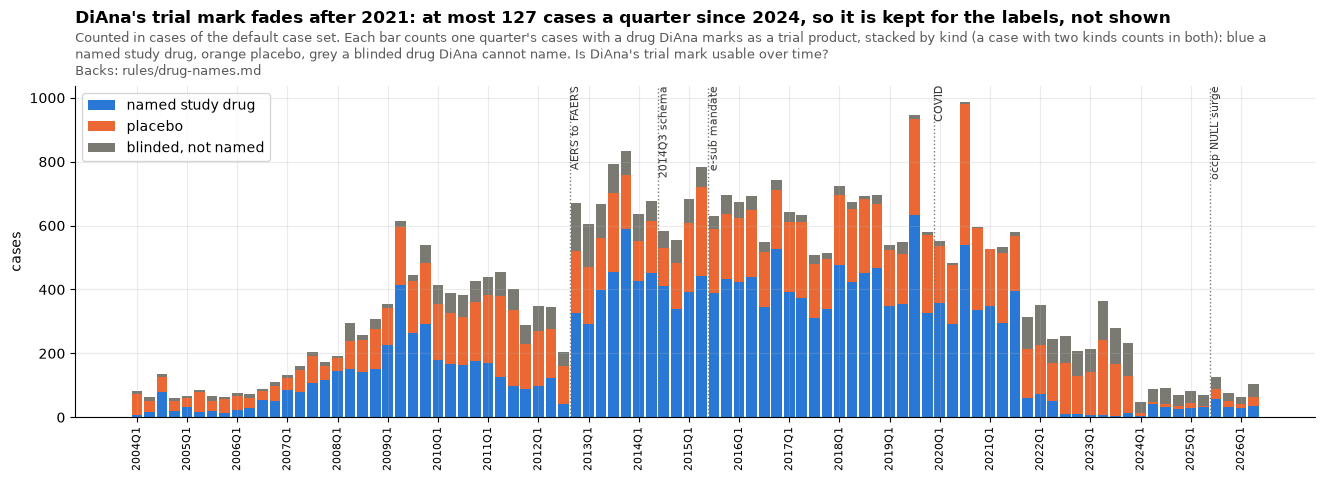

records the release marks diana_trial_T (by name or by prod_ai), default case set: 58,386 in 34,116 cases
named study drugs whose spelling says 'blinded': 49 of 205 spellings, 6,072 records


,cases,drug_records,pct_of_cases
any trial mark,32747,56395,0.161
named study drug,19058,31753,0.094
placebo,12524,18938,0.062
"blinded, not named",3858,5704,0.019


In [16]:
trial = q("""SELECT r.case_key_T, r.quarter_T, r.role_cod, m.substance_T, s.key_T,
  CASE WHEN m.substance_T = 'placebo' THEN 'placebo' WHEN m.substance_T LIKE '%unspecified%' THEN 'blinded, not named' ELSE 'named study drug' END AS flag
FROM rec_T r JOIN spell_T s USING (drugname) JOIN diana_T m USING (key_T) WHERE m.trial_T AND r.dup_kept_T""")
marked = q(
    """SELECT count(*) AS records, count(DISTINCT case_key_T) AS cases FROM rec_T WHERE diana_trial_T AND dup_kept_T"""
).iloc[0]
cases_total = q("SELECT count(*) AS n FROM case_latest_T WHERE dup_kept_T").n[0]
tc = trial.drop_duplicates(["case_key_T", "flag"])
summary = pd.DataFrame(
    {
        "cases": [trial.case_key_T.nunique()]
        + [
            tc[tc.flag == f].shape[0] for f in ["named study drug", "placebo", "blinded, not named"]
        ],
        "drug_records": [len(trial)]
        + [
            int((trial.flag == f).sum())
            for f in ["named study drug", "placebo", "blinded, not named"]
        ],
    },
    index=["any trial mark", "named study drug", "placebo", "blinded, not named"],
)
summary["pct_of_cases"] = (100 * summary.cases / cases_total).round(3)
byq_t = (
    tc.groupby(["quarter_T", "flag"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=byq.quarter_T,
        columns=["named study drug", "placebo", "blinded, not named"],
        fill_value=0,
    )
)
named_trial = trial[trial.flag == "named study drug"]
blinded = named_trial[named_trial.key_T.str.contains("blind")]
fig, ax = plt.subplots(figsize=(16, 4.3))
bottom = np.zeros(len(byq_t))
for c, col in zip(byq_t.columns, [SERIES[0], SERIES[1], SERIES[6]], strict=True):
    ax.bar(range(len(byq_t)), byq_t[c], bottom=bottom, color=col, label=c, width=0.85)
    bottom += byq_t[c].values
ax.set_ylabel("cases")
late = trial[trial.quarter_T >= "2024q1"].groupby("quarter_T").case_key_T.nunique()
title(
    ax,
    f"DiAna's trial mark fades after 2021: at most {late.max():,} cases a quarter since 2024, so it is kept for the labels, not shown",
    "Counted in cases of the default case set. Each bar counts one quarter's cases with a drug DiAna marks as a trial product, stacked by kind "
    "(a case with two kinds counts in both): blue a named study drug, orange placebo, grey a blinded drug DiAna cannot name.",
    "Is DiAna's trial mark usable over time?",
    BACKS,
    width=185,
)
quarter_ticks(ax, byq_t.index)
mark_quarters(ax, byq_t.index)
ax.legend(loc="upper left")
plt.show()
print(
    f"records the release marks diana_trial_T (by name or by prod_ai), default case set: {int(marked.records):,} in {int(marked.cases):,} cases"
)
print(
    f"named study drugs whose spelling says 'blinded': {blinded.key_T.nunique():,} of {named_trial.key_T.nunique():,} spellings, {len(blinded):,} records"
)
summary

**What section 5 shows**, one item per chart:

- **DiAna's trial mark over time.** *Shows:* in cases of the default case set: 32,747 (0.16%) carry a drug DiAna marks by its name: 19,058 a named study drug, 12,524 placebo, 3,858 a blinded drug it cannot name; at most 127 cases a quarter since 2024. With FDA's `prod_ai`, the release marks 58,386 drug records in 34,116 cases (`diana_trial_T`). Of the named study drugs, only those whose spelling says "blinded" are doubtful as the named drug: 49 of 205 spellings, 6,072 records. *Point:* the mark fades from 2021 on, when DiAna stopped mapping most new trial spellings (section 1), so it cannot say which reports came from trials. *So what:* no trial flag on screen; study drugs count under their ingredient, `, trial` removed; a record DiAna marks as a trial product gets no label flag (decision 8); a rule on the raw text would come later.

## 6 · A light check of DiAna's quality, and our corrections

Three looks:

1. **Two samples**: 50 frequent mapped spellings (1,000 drug records or more) and 50 rare ones (one or two records), drawn by a fixed hash of the spelling so the draw repeats. Each is shown with RxNorm's answer and FDA's `prod_ai`; the reading is in the text after the tables.
2. **DiAna against FDA's own `prod_ai`** on every record that has both, both read through the same dictionary, so the only difference is the brand-to-ingredient step.
3. **Our corrections**, as the release applies them: each reviewed line of `mappings/faers/drug_names/` and the records it changes.

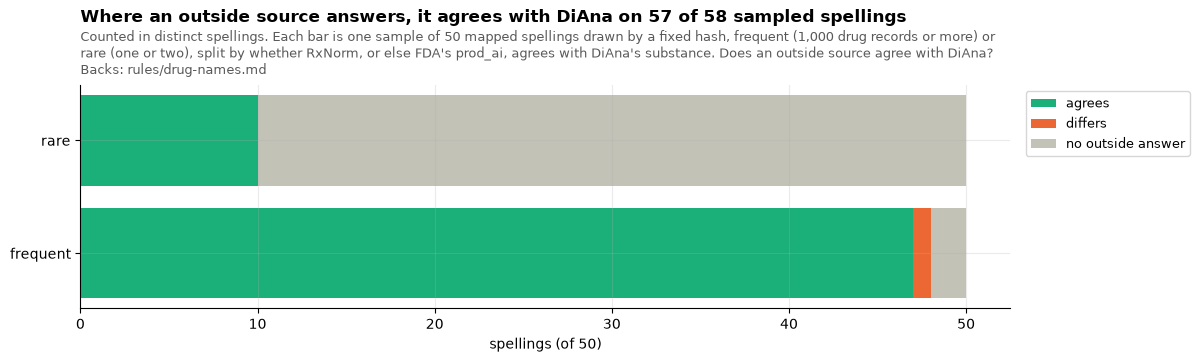

,spelling,drug_records,checked,diana,rxnorm,fda_prod_ai,prod_ai_via_diana,outside_check
0,vit d,5175.0,True,"vitamin d, unspecified",NaN,VITAMIN D NOS,"vitamin d, unspecified",agrees
1,bendroflumethiazide,11190.0,True,bendroflumethiazide,NaN,BENDROFLUMETHIAZIDE,bendroflumethiazide,agrees
2,rizatriptan,6535.0,True,rizatriptan,rizatriptan,RIZATRIPTAN,rizatriptan,agrees
3,carmustine,4429.0,True,carmustine,carmustine,CARMUSTINE,carmustine,agrees
4,fluticasone propionate+salmeterol xinafoate,1825.0,True,fluticasone;salmeterol,NaN,FLUTICASONE PROPIONATE\SALMETEROL XINAFOATE,fluticasone;salmeterol,agrees
5,diovan,57120.0,True,valsartan,valsartan,VALSARTAN,valsartan,agrees
6,vinblastine,6123.0,True,vinblastine,vinblastine,VINBLASTINE,vinblastine,agrees
7,misoprostol,6574.0,True,misoprostol,misoprostol,MISOPROSTOL,misoprostol,agrees
8,voltaren arthritis pain,20877.0,True,diclofenac,NaN,DICLOFENAC SODIUM,diclofenac,agrees
9,onglyza,7225.0,True,saxagliptin,saxagliptin,SAXAGLIPTIN HYDROCHLORIDE,saxagliptin,agrees


,spelling,drug_records,checked,diana,rxnorm,fda_prod_ai,prod_ai_via_diana,outside_check
50,enalapril sandoz (ngx),1.0,False,enalapril,NaN,NaN,NaN,no outside answer
51,rixathon 100 mg concentrate for solution for infusion,1.0,False,rituximab,NaN,RITUXIMAB,rituximab,agrees
52,atropt (atropine sulfate),1.0,False,atropine,NaN,NaN,NaN,no outside answer
53,"tuberculin,purified protein derivative",1.0,False,tuberculin,NaN,TUBERCULIN PURIFIED PROTEIN DERIVATIVE,tuberculin,agrees
54,metamizol alter,2.0,False,metamizole,NaN,NaN,NaN,no outside answer
55,erlotinib 150mg 150mg tab,1.0,False,erlotinib,NaN,NaN,NaN,no outside answer
56,golden seal (hydrastis canadensis),2.0,False,hydrastis spp,NaN,NaN,NaN,no outside answer
57,ethinyloestradiol (ethinylestradiol),2.0,False,ethinylestradiol,NaN,NaN,NaN,no outside answer
58,pegylated interferon-alfa-2b,1.0,False,peginterferon alfa-2b,NaN,PEGINTERFERON ALFA-2B,peginterferon alfa-2b,agrees
59,hydrochloritiazide,1.0,False,hydrochlorothiazide,NaN,NaN,NaN,no outside answer


In [17]:
con.execute(
    "CREATE TEMP TABLE pair_T AS SELECT drugname, prod_ai, count(*) AS n FROM rec_T WHERE prod_ai IS NOT NULL GROUP BY ALL"
)
con.execute(f"""CREATE TEMP TABLE prodai_T AS
WITH p AS (SELECT DISTINCT prod_ai FROM pair_T),
whole AS (SELECT p.prod_ai, d.substance_T FROM p JOIN diana_T d ON d.key_T = {dictionary.key_sql("p.prod_ai")} WHERE d.substance_T IS NOT NULL),
parts AS (SELECT x.prod_ai, array_to_string(list_sort(list_distinct(flatten(list(string_split(d.substance_T, ';'))))), ';') AS substance_T,
                 count(*) FILTER (WHERE d.substance_T IS NULL) AS misses
          FROM (SELECT prod_ai, unnest(string_split(prod_ai, '\\')) AS part FROM p) x
          LEFT JOIN diana_T d ON d.key_T = {dictionary.key_sql("x.part")} GROUP BY 1)
SELECT p.prod_ai, coalesce(whole.substance_T, CASE WHEN parts.misses = 0 THEN parts.substance_T END) AS substance_T
FROM p LEFT JOIN whole USING (prod_ai) LEFT JOIN parts USING (prod_ai)""")
sample = q("""
WITH mapped AS (SELECT s.key_T, sum(s.records_T) AS records_T, any_value(m.substance_raw) AS diana, any_value(m.checked_T) AS checked
                FROM spell_T s JOIN diana_T m USING (key_T) WHERE m.substance_T IS NOT NULL GROUP BY 1),
topai AS (SELECT s.key_T, arg_max(p.prod_ai, p.n) AS fda_prod_ai FROM pair_T p JOIN spell_T s USING (drugname) GROUP BY 1),
pick AS (SELECT 'frequent' AS sample, * FROM (SELECT * FROM mapped WHERE records_T >= 1000 ORDER BY md5(key_T) LIMIT 50)
         UNION ALL SELECT 'rare', * FROM (SELECT * FROM mapped WHERE records_T <= 2 ORDER BY md5(key_T) LIMIT 50))
SELECT pick.sample, pick.key_T AS spelling, pick.records_T AS drug_records, pick.checked, pick.diana, x.rx_ingredients_T AS rxnorm, t.fda_prod_ai, pa.substance_T AS prod_ai_via_diana
FROM pick LEFT JOIN rxname_T x USING (key_T) LEFT JOIN topai t USING (key_T) LEFT JOIN prodai_T pa ON pa.prod_ai = t.fda_prod_ai
ORDER BY pick.sample, md5(pick.key_T)""")


def reference(row):
    """Agreement with an outside answer: RxNorm first, else FDA's prod_ai read through DiAna."""
    d = re.sub(r",\s*trial", "", row.diana)
    if isinstance(row.rxnorm, str):
        return "agrees" if compare(d, row.rxnorm).startswith("same") else "differs"
    if isinstance(row.prod_ai_via_diana, str):
        return "agrees" if d == row.prod_ai_via_diana else "differs"
    return "no outside answer"


sample["outside_check"] = sample.apply(reference, axis=1)
tab = (
    sample.groupby(["sample", "outside_check"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["agrees", "differs", "no outside answer"], fill_value=0)
)
fig, ax = plt.subplots(figsize=(12, 2.9))
left = np.zeros(len(tab))
for c, col in zip(tab.columns, [SERIES[2], SERIES[1], SERIES[7]], strict=True):
    ax.barh(tab.index, tab[c], left=left, color=col, label=c)
    left += tab[c].values
ax.set_xlabel("spellings (of 50)")
title(
    ax,
    f"Where an outside source answers, it agrees with DiAna on {tab.agrees.sum()} of {tab.agrees.sum() + tab.differs.sum()} sampled spellings",
    "Counted in distinct spellings. Each bar is one sample of 50 mapped spellings drawn by a fixed hash, frequent (1,000 drug records or more) or rare (one or two), "
    "split by whether RxNorm, or else FDA's prod_ai, agrees with DiAna's substance.",
    "Does an outside source agree with DiAna?",
    BACKS,
    width=140,
)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()
display(sample[sample["sample"] == "frequent"].drop(columns="sample"))
sample[sample["sample"] == "rare"].drop(columns="sample")

**Reading the samples.** All 100 were read against the product, not only the outside check.

- **Frequent (1,000 records or more, all checked by hand by DiAna).** 47 agree with RxNorm or FDA's `prod_ai`, 1 differs, 2 have no outside answer. By reading, 48 are right. Wrong: the Dianeal spellings (`dianeal low calcium ...`, `dianeal pd4 ... 2.5 meq/l calcium`) drop the calcium chloride the solution contains; *low calcium* is not *no calcium*. Debatable: `refresh tears` is the class `artificial tears`, where FDA's `prod_ai` names carboxymethylcellulose.
- **Rare (seen once or twice, none checked by hand).** Only 10 have an outside answer, and all 10 agree. By reading none is wrong, and one could not be verified (`bromed` as bromhexine). Typos (`hydrochloritiazide`, `acetazolamid`), foreign brands (Eutimil, Dilatrend, Coltrax, Cernos Depot) and names with the ingredient in brackets are handled well. `tums` becomes `calcium`, by DiAna's no-salts rule.
- So the hand-checked core is good, and so is the unchecked tail where it maps at all.

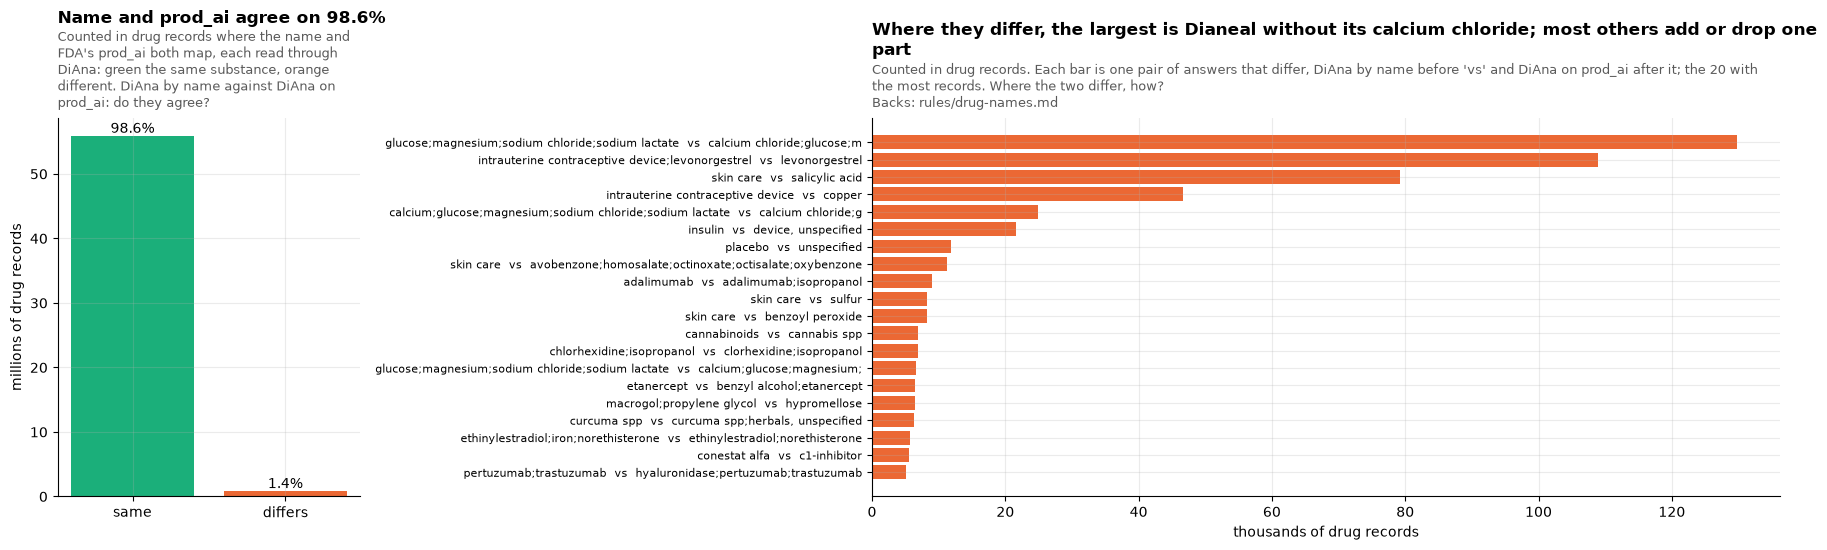

,diana,prod_ai_via_diana,drug_records,name_pairs,example_name,example_prod_ai,same
63,glucose;magnesium;sodium chloride;sodium lactate,calcium chloride;glucose;magnesium;sodium chloride;sodium lactate,129740.0,19,DIANEAL LOW CALCIUM PERITONEAL DIALYSIS SOLUTION WITH DEXTROSE,CALCIUM CHLORIDE\DEXTROSE\MAGNESIUM CHLORIDE\SODIUM CHLORIDE\SODIU...,False
814,intrauterine contraceptive device;levonorgestrel,levonorgestrel,108939.0,7,MIRENA,LEVONORGESTREL,False
338,skin care,salicylic acid,79199.0,8,PROACTIV DEEP CLEANSING WASH,SALICYLIC ACID,False
904,intrauterine contraceptive device,copper,46658.0,12,PARAGARD T 380A,COPPER,False
6320,calcium;glucose;magnesium;sodium chloride;sodium lactate,calcium chloride;glucose;magnesium;sodium chloride;sodium lactate,24938.0,15,DELFLEX,CALCIUM CHLORIDE\DEXTROSE\MAGNESIUM CHLORIDE\SODIUM CHLORIDE\SODIU...,False
1239,insulin,"device, unspecified",21669.0,5,SOLOSTAR,DEVICE,False
483,placebo,unspecified,11914.0,18,PLACEBO,UNSPECIFIED INGREDIENT,False
7994,skin care,avobenzone;homosalate;octinoxate;octisalate;oxybenzone,11192.0,1,PROACTIV SOLUTION DAILY PROTECTION PLUS SUNSCREEN SPF 30,AVOBENZONE\HOMOSALATE\OCTINOXATE\OCTISALATE\OXYBENZONE,False
7865,adalimumab,adalimumab;isopropanol,9041.0,1,ADALIMUMAB,ADALIMUMAB\ISOPROPYL ALCOHOL,False
883,skin care,sulfur,8273.0,1,PROACTIV SKIN PURIFYING MASK,SULFUR,False


In [18]:
agree = q("""SELECT m.substance_T AS diana, p.substance_T AS prod_ai_via_diana, sum(x.n) AS drug_records, count(*) AS name_pairs,
  arg_max(x.drugname, x.n) AS example_name, arg_max(x.prod_ai, x.n) AS example_prod_ai
FROM pair_T x JOIN spell_T s USING (drugname) JOIN diana_T m USING (key_T) JOIN prodai_T p ON p.prod_ai = x.prod_ai
WHERE m.substance_T IS NOT NULL AND p.substance_T IS NOT NULL AND NOT m.unspecified_T GROUP BY 1, 2""")
agree["same"] = agree.diana == agree.prod_ai_via_diana
share = agree.groupby("same").drug_records.sum()
disag = agree[~agree.same].sort_values("drug_records", ascending=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 5.6), gridspec_kw={"width_ratios": [0.5, 1.5]})
a1.bar(
    ["same", "differs"],
    [share.get(True, 0) / 1e6, share.get(False, 0) / 1e6],
    color=[SERIES[2], SERIES[1]],
)
for xx, v in enumerate([share.get(True, 0), share.get(False, 0)]):
    a1.text(xx, v / 1e6, f"{100 * v / share.sum():.1f}%", ha="center", va="bottom")
a1.set_ylabel("millions of drug records")
title(
    a1,
    f"Name and prod_ai agree on {100 * share.get(True, 0) / share.sum():.1f}%",
    "Counted in drug records where the name and FDA's prod_ai both map, each read through DiAna: green the same substance, orange different.",
    "DiAna by name against DiAna on prod_ai: do they agree?",
    width=44,
)
t = disag.head(20)
a2.barh(
    [f"{d}  vs  {p}"[:80] for d, p in zip(t.diana[::-1], t.prod_ai_via_diana[::-1], strict=True)],
    t.drug_records[::-1] / 1e3,
    color=SERIES[1],
)
a2.set_xlabel("thousands of drug records")
title(
    a2,
    "Where they differ, the largest is Dianeal without its calcium chloride; most others add or drop one part",
    "Counted in drug records. Each bar is one pair of answers that differ, DiAna by name before 'vs' and DiAna on prod_ai after it; the 20 with the most records.",
    "Where the two differ, how?",
    BACKS,
    width=138,
)
a2.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
disag.head(25)

2946083476.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


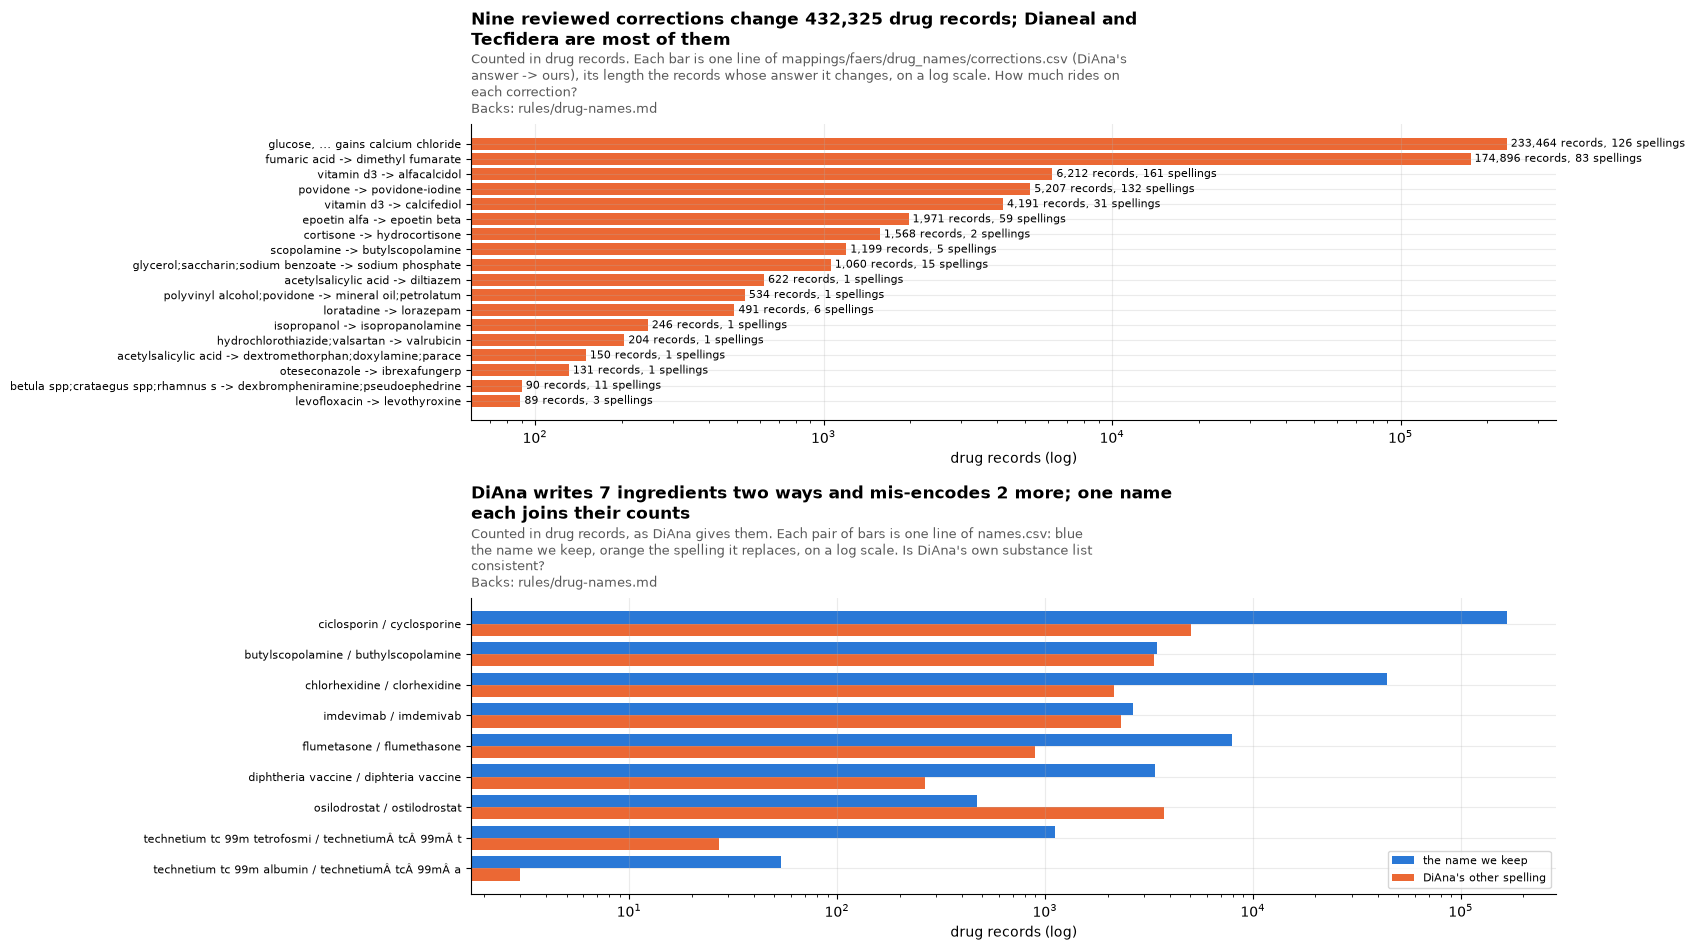

,correction,drug_records,spellings
0,"glucose, ... gains calcium chloride",233464,126
1,fumaric acid -> dimethyl fumarate,174896,83
3,vitamin d3 -> alfacalcidol,6212,161
5,povidone -> povidone-iodine,5207,132
4,vitamin d3 -> calcifediol,4191,31
2,epoetin alfa -> epoetin beta,1971,59
10,cortisone -> hydrocortisone,1568,2
16,scopolamine -> butylscopolamine,1199,5
7,glycerol;saccharin;sodium benzoate -> sodium phosphate,1060,15
6,acetylsalicylic acid -> diltiazem,622,1


,combinations,not_sorted
0,51837,64


,name,drug_records,diana_also_writes,its_records
0,ciclosporin,166455,cyclosporine,5038
1,butylscopolamine,3442,buthylscopolamine,3354
2,chlorhexidine,43978,clorhexidine,2146
3,imdevimab,2644,imdemivab,2309
4,flumetasone,7946,flumethasone,895
5,diphtheria vaccine,3379,diphteria vaccine,265
6,osilodrostat,472,ostilodrostat,3729
7,technetium tc 99m tetrofosmin,1115,technetiumÂ tcÂ 99mÂ tetrofosmin,27
8,technetium tc 99m albumin,54,technetiumÂ tcÂ 99mÂ albumin,3


,diana,ours,drug_records,spellings
0,glucose;magnesium;sodium chloride;sodium lactate,calcium chloride;glucose;magnesium;sodium chloride;sodium lactate,233464,126
1,fumaric acid,dimethyl fumarate,174896,83
2,vitamin d3,alfacalcidol,6212,161
3,povidone,povidone-iodine,5207,132
4,cyclosporine,ciclosporin,5038,1
5,vitamin d3,calcifediol,4191,31
6,ostilodrostat,osilodrostat,3729,1
7,buthylscopolamine,butylscopolamine,3354,1
8,casirivimab;imdemivab,casirivimab;imdevimab,2309,4
9,clorhexidine;isopropanol,chlorhexidine;isopropanol,2146,1


In [19]:
# our corrections as the release applies them: each reviewed line, the records it changes, and DiAna's answer before
fixes = pd.read_csv(
    rulebook.data_root() / rulebook.value("drug-names", "corrections"), dtype=str
).fillna("")
names_csv = pd.read_csv(rulebook.data_root() / rulebook.value("drug-names", "names"), dtype=str)
changed = q("""SELECT m.substance_T AS diana, r.substance_T AS ours, count(*) AS drug_records, count(DISTINCT s.key_T) AS spellings
FROM rec_T r JOIN spell_T s USING (drugname) JOIN diana_T m USING (key_T)
WHERE r.substance_source_T = 'correction' AND m.substance_T IS NOT NULL GROUP BY 1, 2 ORDER BY 3 DESC""")


def canonical(d):
    return ";".join(sorted({p.strip() for p in d.split(";")}))


def label(diana, ours):
    a, b = set(diana.split(";")), set(ours.split(";"))
    return (
        f"{diana.split(';')[0]}, ... gains {', '.join(sorted(b - a))}"
        if a < b
        else f"{diana[:34]} -> {ours[:34]}"
    )


by_fix = []
for f in fixes.itertuples():
    hit = changed[
        (changed.ours == f.substance) & (changed.diana.apply(canonical) == f.diana_substance)
    ]
    by_fix.append(
        (
            label(f.diana_substance, f.substance),
            int(hit.drug_records.sum()),
            int(hit.spellings.sum()),
        )
    )
by_fix = pd.DataFrame(by_fix, columns=["correction", "drug_records", "spellings"]).sort_values(
    "drug_records", ascending=False
)
TWINS = list(zip(names_csv.name, names_csv.diana_name, strict=True))
part = (
    q("""SELECT trim(c) AS substance, count(*) AS drug_records FROM rec_T r JOIN spell_T s USING (drugname) JOIN diana_T m USING (key_T),
  unnest(string_split(m.substance_T, ';')) t(c) WHERE m.substance_T IS NOT NULL GROUP BY 1""")
    .set_index("substance")
    .drug_records
)
vocab = pd.DataFrame(
    [(a, int(part.get(a, 0)), b, int(part.get(b, 0))) for a, b in TWINS],
    columns=["name", "drug_records", "diana_also_writes", "its_records"],
)
unsorted = q("""SELECT count(*) AS combinations, count(*) FILTER (WHERE substance_T <> array_to_string(list_sort(string_split(substance_T, ';')), ';')) AS not_sorted
FROM diana_T WHERE substance_T LIKE '%;%'""")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={"hspace": 0.6})
a1.barh(by_fix.correction[::-1], by_fix.drug_records[::-1], color=SERIES[1])
a1.set_xscale("log")
a1.set_xlabel("drug records (log)")
for yy, (v, n) in enumerate(zip(by_fix.drug_records[::-1], by_fix.spellings[::-1], strict=True)):
    a1.text(v, yy, f" {v:,} records, {n} spellings", va="center", fontsize=8)
title(
    a1,
    f"Nine reviewed corrections change {by_fix.drug_records.sum():,} drug records; Dianeal and Tecfidera are most of them",
    "Counted in drug records. Each bar is one line of mappings/faers/drug_names/corrections.csv (DiAna's answer -> ours), its length the records whose answer it changes, on a log scale.",
    "How much rides on each correction?",
    BACKS,
    width=100,
)
a1.tick_params(axis="y", labelsize=8)
tw = vocab[vocab.its_records > 0]
y = np.arange(len(tw))
a2.barh(y - 0.2, tw.drug_records, 0.4, color=SERIES[0], label="the name we keep")
a2.barh(y + 0.2, tw.its_records, 0.4, color=SERIES[1], label="DiAna's other spelling")
a2.set_yticks(y)
a2.set_yticklabels(
    [f"{a[:28]} / {b[:22]}" for a, b in zip(tw.name, tw.diana_also_writes, strict=True)], fontsize=8
)
a2.invert_yaxis()
a2.set_xscale("log")
a2.set_xlabel("drug records (log)")
twice = int((~tw.diana_also_writes.str.contains("\u00a0")).sum())
title(
    a2,
    f"DiAna writes {twice} ingredients two ways and mis-encodes {len(tw) - twice} more; one name each joins their counts",
    "Counted in drug records, as DiAna gives them. Each pair of bars is one line of names.csv: blue the name we keep, orange the spelling it replaces, on a log scale.",
    "Is DiAna's own substance list consistent?",
    BACKS,
    width=96,
)
a2.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(by_fix, unsorted, vocab)
changed.head(20)

**What section 6 shows**, one item per chart:

- **The two samples.** *Shows:* in distinct spellings: where RxNorm or FDA's `prod_ai` answers, it agrees with DiAna on 57 of 58 sampled spellings; by reading, the frequent sample's errors are the Dianeal solutions without their calcium chloride, and the rare sample has none. *Point:* the hand-checked core is good, and so is the unchecked tail where it maps at all. *So what:* DiAna as the seed (decision 1). 100 spellings cannot rule out an error rate of a few percent, so the corrections come from reading the disagreements in the next charts.
- **DiAna by name against DiAna on FDA's `prod_ai`.** *Shows:* in drug records: they agree on 98.6% of the records where both map. The largest disagreement is Dianeal without its calcium chloride (129,740 records), then Mirena's added device part, Proactiv products as the class `skin care`, copper IUDs, insulin against a device; `prod_ai` is itself noisy (Protonix coded as omeprazole, kits carrying the alcohol swab). *Point:* FDA's own field finds DiAna's errors, but it is no referee. *So what:* `prod_ai` is the fallback, not the judge; the Dianeal correction (decision 7).
- **Our corrections, and DiAna's twin names.** *Shows:* in drug records: nine reviewed corrections change 427,713 records: the Dianeal family gains calcium chloride (233,464 records, 126 spellings; FDA's `prod_ai` lists it on every record that carries one); Tecfidera and the other dimethyl fumarate spellings leave fumaric acid (174,896); alfacalcidol (6,212) and calcifediol (4,191) leave vitamin D3; Betadine and the spellings naming povidone-iodine leave povidone (5,207); NeoRecormon is epoetin beta (1,971); Fleet Phospho-soda is sodium phosphate (1,060); Cartia is diltiazem (622; 451 of them US reports); Drixoral is its two ingredients (90). Seven ingredients DiAna writes two ways, and two radiopharmaceuticals whose spaces its file mis-encodes, take one name each: ciclosporin (166,455 records) absorbs cyclosporine (5,038), osilodrostat (472) absorbs ostilodrostat (3,729). 64 of DiAna's 51,837 combinations are out of order; the step sorts every set. With the corrections that arrive through `prod_ai`, 445,865 records say their ingredients are our correction. *Point:* a short reviewed list fixes the errors that move counts, and each record says it was corrected. *So what:* the corrections ship in `mappings/faers/drug_names/`, one line each with its reason and evidence, DiAna's file untouched, and the list goes to DiAna's authors (decision 7).

## 7 · What the drug classes and label steps receive

The WHO drug classes step (ATC) and the RxNorm codes join on the substance this step gives each drug record (`drug_substance_T`); the label flags join through the RxNorm code.

- **One substance per drug record.** DiAna's substance for the record's drug name, our corrections applied and `, trial` removed; where the name has none, FDA's `prod_ai` read through the same dictionary. The raw `drugname` and `prod_ai` stay as FDA published them.
- **Combinations arrive whole.** A combination keeps its full ingredient set on the record, sorted and joined with `;` (`sacubitril;valsartan`), so a later step can look up the whole set's own code before it uses one row per ingredient (`drug_ingredient_T`).
- **Counted on the default case set, suspects as PS or SS.** A record counts as **named** when every part of its substance is a named ingredient: not `unspecified`, not a class term. It is **codeable by name** when every part also matches an RxNorm prescribable ingredient by name (the comparison of section 3), an approximation of what the RxNorm step will find.

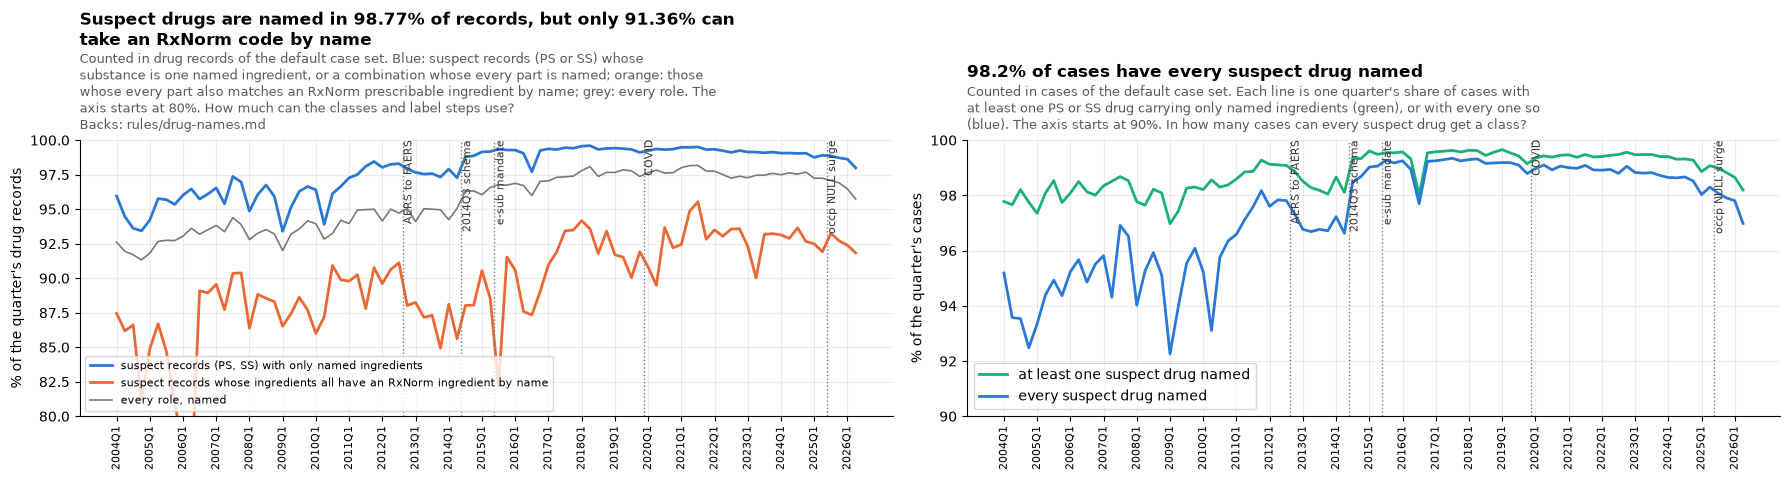

suspect records that are combinations: 6.78%


,drug_records,via_prod_ai,suspect_records,suspect_codeable,distinct_substances,pct_records,pct_suspect_records
status,,,,,,,
one named ingredient,66227811,28729,37765095,35453170,5788,90.44,92.10
"combination, every part named",4567532,85442,2732877,2006747,8258,6.24,6.67
combination with an unspecified part,186717,5940,46445,0,837,0.25,0.11
unspecified or class term,1242006,18536,301661,0,117,1.70,0.74
no substance,1004713,0,156612,0,0,1.37,0.38


,suspect_named_min,every_suspect_named_min,lowest_quarter,every_suspect_named_max
era,,,,
"AERS, to 2012Q3",93.40,92.26,2009q1,98.17
"FAERS, 2012Q4 on",97.27,96.63,2014q2,99.34


,quarter_T,suspect_named,suspect_codeable,all_named,cases,every_suspect_named,a_suspect_named,no_suspect_listed
0,2004q1,95.95,87.45,92.62,49948,95.19,97.78,0.00
34,2012q3,98.30,91.12,94.72,89524,97.81,99.09,0.00
35,2012q4,97.90,88.03,95.04,216899,97.34,98.86,0.01
41,2014q2,97.27,85.61,95.05,183779,96.63,98.11,0.00
42,2014q3,98.80,88.02,96.29,194858,98.49,99.35,0.00
64,2020q1,99.24,90.82,97.63,372917,98.97,99.34,0.00
80,2024q1,99.06,93.14,97.49,327274,98.65,99.40,0.00
84,2025q1,98.75,92.49,97.24,317810,98.03,98.86,0.00
87,2025q4,98.72,92.71,96.91,338670,97.91,98.83,0.00
88,2026q1,98.63,92.39,96.46,362268,97.81,98.65,0.00


In [20]:
SUSPECT = "('PS', 'SS')"
STATUS = [
    "one named ingredient",
    "combination, every part named",
    "combination with an unspecified part",
    "unspecified or class term",
    "no substance",
]
con.execute("""CREATE OR REPLACE TEMP MACRO status_of(sub) AS CASE
  WHEN sub IS NULL THEN 'no substance'
  WHEN sub NOT LIKE '%;%' AND (sub LIKE '%unspecified%' OR sub IN ('no medication', 'no drug')) THEN 'unspecified or class term'
  WHEN sub NOT LIKE '%;%' THEN 'one named ingredient'
  WHEN sub LIKE '%unspecified%' THEN 'combination with an unspecified part'
  ELSE 'combination, every part named' END""")
codeable = pd.DataFrame({"substance_T": subs.substance_T, "codeable_T": subs.codeable})
con.register("codeable_df", codeable)
con.execute(f"""CREATE TEMP TABLE record_T AS
SELECT r.case_key_T, r.quarter_T, r.role_cod IN {SUSPECT} AS suspect_T, r.substance_T, r.substance_source_T,
       status_of(r.substance_T) AS status_T, coalesce(k.codeable_T, false) AS codeable_T
FROM rec_T r LEFT JOIN codeable_df k USING (substance_T) WHERE r.dup_kept_T""")
carried = (
    q("""SELECT status_T AS status, count(*) AS drug_records, count(*) FILTER (WHERE substance_source_T = 'diana_prod_ai') AS via_prod_ai,
  count(*) FILTER (WHERE suspect_T) AS suspect_records, count(*) FILTER (WHERE suspect_T AND codeable_T) AS suspect_codeable,
  count(DISTINCT substance_T) AS distinct_substances FROM record_T GROUP BY 1""")
    .set_index("status")
    .reindex(STATUS)
)
carried["pct_records"] = (100 * carried.drug_records / carried.drug_records.sum()).round(2)
carried["pct_suspect_records"] = (
    100 * carried.suspect_records / carried.suspect_records.sum()
).round(2)
named = "status_T IN ('one named ingredient', 'combination, every part named')"
rq = q(f"""SELECT quarter_T, 100.0 * avg(({named})::INT) FILTER (WHERE suspect_T) AS suspect_named,
  100.0 * avg(codeable_T::INT) FILTER (WHERE suspect_T) AS suspect_codeable, 100.0 * avg(({named})::INT) AS all_named
FROM record_T GROUP BY 1 ORDER BY 1""")
cq = q(f"""WITH c AS (SELECT case_key_T, any_value(quarter_T) AS quarter_T, count(*) FILTER (WHERE suspect_T) AS suspects,
                     count(*) FILTER (WHERE suspect_T AND {named}) AS suspects_named FROM record_T GROUP BY 1),
k AS (SELECT c2.case_key_T, c2.quarter_T, coalesce(c.suspects, 0) AS suspects, coalesce(c.suspects_named, 0) AS suspects_named
      FROM case_latest_T c2 LEFT JOIN c USING (case_key_T) WHERE c2.dup_kept_T)
SELECT quarter_T, count(*) AS cases, 100.0 * avg((suspects > 0 AND suspects_named = suspects)::INT) AS every_suspect_named,
  100.0 * avg((suspects_named > 0)::INT) AS a_suspect_named, 100.0 * avg((suspects = 0)::INT) AS no_suspect_listed
FROM k GROUP BY 1 ORDER BY 1""")
sus = carried.suspect_records.sum()
named_pct = (
    100
    * carried.loc[
        ["one named ingredient", "combination, every part named"], "suspect_records"
    ].sum()
    / sus
)
code_pct = 100 * carried.suspect_codeable.sum() / sus
combo_pct = (
    100
    * carried.loc[
        ["combination, every part named", "combination with an unspecified part"], "suspect_records"
    ].sum()
    / sus
)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(18, 4.9))
x = range(len(rq))
a1.plot(
    x,
    rq.suspect_named,
    label="suspect records (PS, SS) with only named ingredients",
    color=SERIES[0],
)
a1.plot(
    x,
    rq.suspect_codeable,
    label="suspect records whose ingredients all have an RxNorm ingredient by name",
    color=SERIES[1],
)
a1.plot(x, rq.all_named, label="every role, named", color=SERIES[6], lw=1.2)
a1.set_ylim(80, 100)
a1.set_ylabel("% of the quarter's drug records")
title(
    a1,
    f"Suspect drugs are named in {named_pct:.2f}% of records, but only {code_pct:.2f}% can take an RxNorm code by name",
    "Counted in drug records of the default case set. Blue: suspect records (PS or SS) whose substance is one named ingredient, or a combination whose every part is named; "
    "orange: those whose every part also matches an RxNorm prescribable ingredient by name; grey: every role. The axis starts at 80%.",
    "How much can the classes and label steps use?",
    BACKS,
    width=95,
)
quarter_ticks(a1, rq.quarter_T)
mark_quarters(a1, rq.quarter_T)
a1.legend(loc="lower left", fontsize=8)
a2.plot(
    range(len(cq)), cq.a_suspect_named, label="at least one suspect drug named", color=SERIES[2]
)
a2.plot(range(len(cq)), cq.every_suspect_named, label="every suspect drug named", color=SERIES[0])
a2.set_ylim(90, 100)
a2.set_ylabel("% of the quarter's cases")
t0 = cq[["cases"]].sum().iloc[0]
every = (cq.cases * cq.every_suspect_named / 100).sum() / t0 * 100
title(
    a2,
    f"{every:.1f}% of cases have every suspect drug named",
    "Counted in cases of the default case set. Each line is one quarter's share of cases with at least one PS or SS drug carrying only named ingredients (green), "
    "or with every one so (blue). The axis starts at 90%.",
    "In how many cases can every suspect drug get a class?",
    width=90,
)
quarter_ticks(a2, cq.quarter_T)
mark_quarters(a2, cq.quarter_T)
a2.legend(loc="lower left")
plt.tight_layout()
plt.show()
print(f"suspect records that are combinations: {combo_pct:.2f}%")
eras = rq.merge(cq, on="quarter_T").assign(
    era=lambda d: np.where(d.quarter_T < "2012q4", "AERS, to 2012Q3", "FAERS, 2012Q4 on")
)
era_range = (
    eras.groupby("era")
    .agg(
        suspect_named_min=("suspect_named", "min"),
        every_suspect_named_min=("every_suspect_named", "min"),
        lowest_quarter=("every_suspect_named", lambda s: eras.quarter_T[s.idxmin()]),
        every_suspect_named_max=("every_suspect_named", "max"),
    )
    .round(2)
)
display(carried, era_range)
SHOW = [
    "2004q1",
    "2012q3",
    "2012q4",
    "2014q2",
    "2014q3",
    "2020q1",
    "2024q1",
    "2025q1",
    "2025q4",
    "2026q1",
    "2026q2",
]
rq.merge(cq, on="quarter_T").round(2).query("quarter_T in @SHOW")

**What section 7 shows**, one item per chart:

- **Named and codeable records by quarter, and cases with every suspect drug named.** *Shows:* in drug records of the default case set: 90.44% carry one named ingredient, 6.24% a combination whose every part is named, 0.25% a combination with an unspecified part (Prempro is `estrogens, unspecified;medroxyprogesterone`), 1.70% only an unspecified or class term, 1.37% nothing. Of the suspect records (PS or SS), 98.77% are named but 91.36% can take an RxNorm code by name, and 6.78% are combinations. In cases, 98.2% have every suspect drug named; by quarter 96.63% to 99.34% in FAERS (lowest 2014Q2) and 92.26% to 98.17% in AERS, which has no `prod_ai` to fall back on; 2026Q2 is 96.98%. *Point:* the classes and label steps receive a named ingredient for nearly every suspect drug; the RxNorm code is the narrower gate. *So what:* combinations arrive whole on the record (decision 1); RxNorm codes from the spelling first, then DiAna (decision 2); suspect means PS and SS here as everywhere (decision 4).

## Rules-page cards from this notebook

The three cards of this notebook, computed by the same functions the release build calls (`src/open_altio/faers/insights/cards/drug_names.py`) on the release this notebook reads, each the evidence for rule `drug-names`: one medicine written hundreds of ways (a search for its brand misses the rest), medicines patients take alongside the suspect one counted in every role, and a brand that changed its ingredient. Each is written to `notebooks/out/cards/` (or `$OPEN_ALTIO_INSIGHTS_OUT/cards/`).

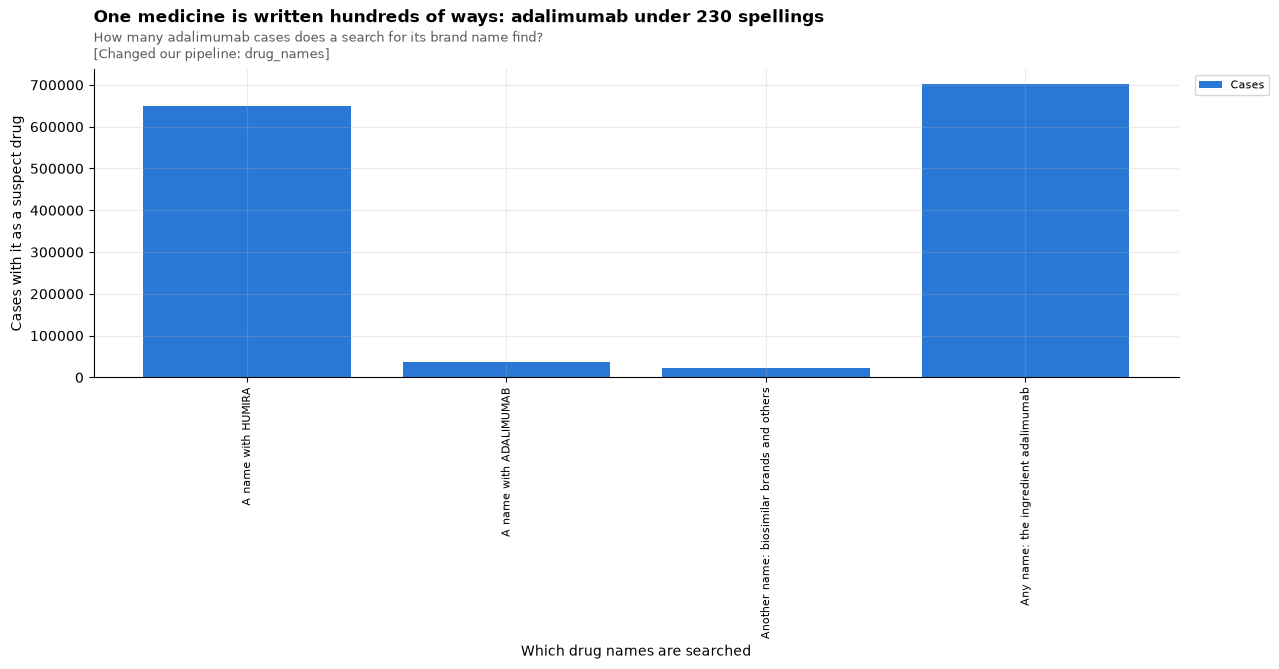

FDA publishes each drug name as the reporter typed it, so adalimumab reaches FAERS as HUMIRA, ADALIMUMAB, misspellings and every biosimilar brand. A search for humira finds 650,245 of the 702,102 cases with adalimumab as a suspect (93%); searching by ingredient finds them all.


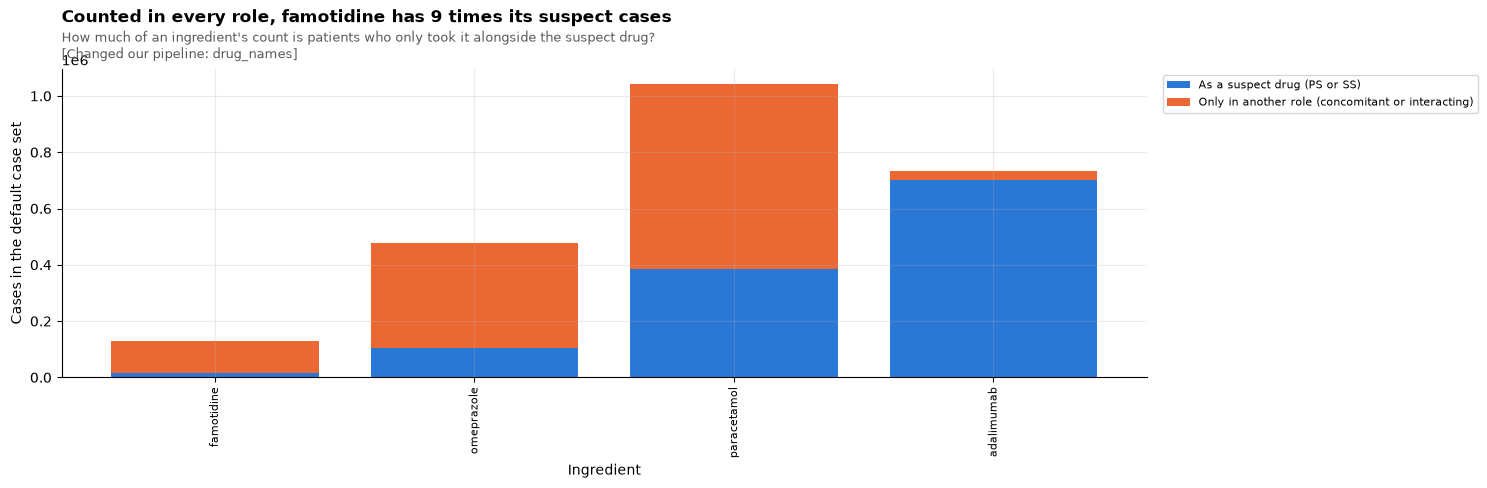

43% of FAERS drug records are concomitant: medicines the patient also took, not the one suspected. Famotidine is a suspect drug in 14,058 cases but appears in 127,743, so a count over every role mostly measures how many patients take it.


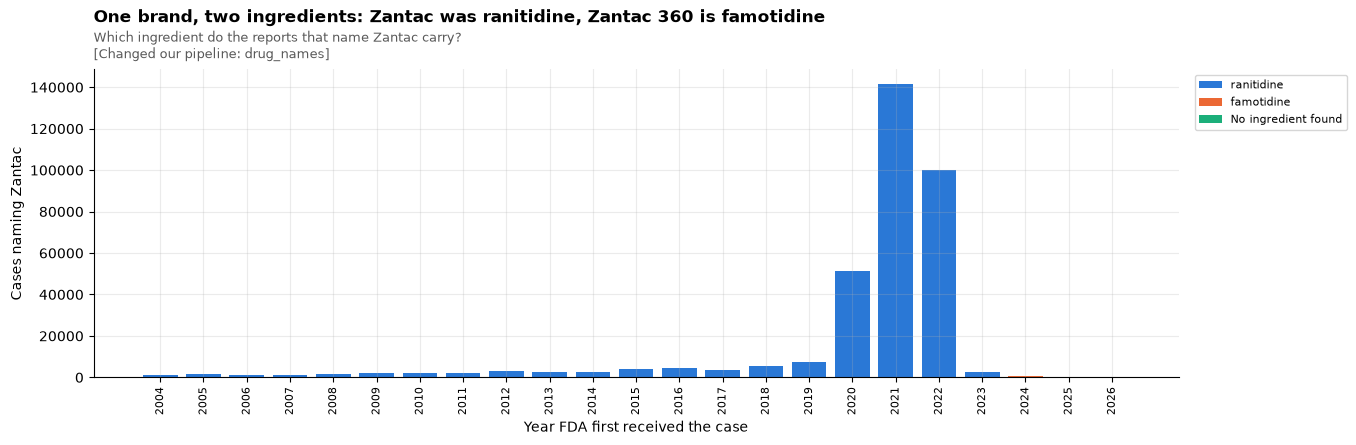

After ranitidine was withdrawn in 2020 the Zantac name came back as Zantac 360, which is famotidine. Of the cases naming Zantac, 342,974 carry ranitidine and 201 famotidine, so a search for the brand mixes two medicines and a search by ingredient does not.
notebooks/out/cards/05_drug_names.json


In [21]:
cards = compute_cards(
    con,
    [
        "one_medicine_many_spellings",
        "background_drugs_counted_every_role",
        "brand_changes_ingredient",
    ],
)
for card in cards:
    plot_card(card)
print(write_cards(cards, "05_drug_names"))

## Decisions

The decision each question of this notebook backs, with its numbers. Counts are drug records unless they say cases.

1. **DiAna as the seed.** Each drug record gets its ingredients from DiAna's 2023 key, with FDA's `prod_ai` where the name has none: 98.64% of drug records, 1.36% left without. The dictionary is read by its checksum and credited (CC BY 4.0), a changed file stops the build, and `mappings/faers/drug_names/` holds only our reviewed corrections. Combinations stay whole on the record, with one row per ingredient beside it.
2. **RxNorm ingredient codes, a later step not in this release,** in their own column beside the DiAna ingredient: the spelling's own exact RxNorm match first (ingredient, salt, multiple ingredient or brand, current prescribable content), else DiAna's substance through a short reviewed list of INN-to-US name pairs. The code can be more precise than the name: Lantus counts under insulin and is coded insulin glargine. 92% of the records with a named substance can take a code by name; the methods page states the uncoded share (foreign, withdrawn, vague).
3. **Search by ingredient.** Every spelling is listed with its count and can be unticked, and a text search adds unmapped spellings. The default is "any product containing" the ingredient (valsartan as PS or SS: 167,019 cases, against 34,317 alone), with "exact product" beside it; the statistics count the same unit.
4. **PS and SS by default, everywhere,** every role one tick box away (PS, SS, I, C); FDA's role codes are never recoded, so I is not merged into SS. Concomitant records (43%) stay in the data, mapped, shown in cases and counted under "every role". DiAna's own tool counts every role by default, so our counts are lower (famotidine: 11,659 cases as PS or SS, 124,199 in any role), and the methods page says so.
5. **Ship with the residue as it is.** Records with no ingredient keep FDA's spelling, a text search finds them, and the methods page states the share: 1.36% of drug records. New US brands RxNorm knows would get a code by decision 2. Next, reviewed rules (about 64% of the residue is their kind), then model proposals for spellings seen 5 times or more, newest quarters first: the first drug-name update.
6. **Our own quarterly top-up, not built yet.** The rules and model proposals of decision 5 run on each quarter's new spellings seen 5 times or more (140 to 390 a quarter since 2023) before the release is published, and DiAna's updates are still taken, by moving the rule to their new checksum. DiAna maps the new names that become common but lags on the newest: records with no DiAna substance in their own quarter went from 15,758 in 2025Q1 to 36,489 in 2026Q2.
7. **Reviewed corrections beside DiAna's file, never edits to it:** the nine corrections and nine names of section 6 (445,865 records), each one line with its reason and evidence. They go to DiAna's authors, and a correction is dropped once DiAna fixes it. Insulin and tenofovir stay grouped for counting; splitting them is a change of its own.
8. **No trial flag on screen,** because DiAna's mark fades from 2021 on. Study drugs count under their ingredient, `, trial` removed. A record DiAna marks as a trial product (named study drug, placebo, blinded: 58,386 records) would get no label flag. A rule on the raw text would come later.
9. **The label follows the unit counted,** for the label flags still to be built. An ingredient ("any product containing" valsartan) is judged against that ingredient's own single-ingredient label (the originator's, today's version); an exact combination (Entresto) against its own label, through its own RxNorm code; a combination with no code of its own gets "no label found". The methods page says that valsartan's count includes Entresto reports but is judged against valsartan's label. Labels are not matched by company: generics carry the originator's safety labelling, biosimilars mirror their reference, and FAERS often cannot say whose product it was. Where an ingredient's labels differ by form (diclofenac gel or tablets), the report's route family picks the label: FDA's route first, then the dose form, then form words in the spelling; where they disagree the form is unknown, and the flag shows the split rather than guessing.